In [ ]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount("/content/drive", force_remount=False)

DATA_DIR = Path("/content/drive/MyDrive/ASD_SSD_Overhaul_Data")
all_tables = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in {".csv", ".tsv"} and not p.name.startswith(".")
)

def read_table(path):
    sep = "\t" if path.suffix.lower() == ".tsv" else ","
    return pd.read_csv(path, sep=sep, na_values=["n/a", "NA", "NaN", ""])

def normalize_pid(series):
    return series.astype(str).str.strip()

cnp_files = [p for p in all_tables if not p.name.lower().startswith("openneuro_ds")]
cnp_files.sort(key=lambda p: (
    0 if "ucla_cnp_behavioral" in p.name.lower()
    else 1 if "ucla_cnp_participants" in p.name.lower()
    else 2,
    p.name.lower(),
))

df = None
merged_sources = []
for path in cnp_files:
    tmp = read_table(path)
    pid_col = next((c for c in tmp.columns if c.lower() in {"participant_id", "subject_id", "sub_id", "id"}), None)
    if pid_col is None:
        continue
    tmp = tmp.rename(columns={pid_col: "participant_id"})
    tmp["participant_id"] = normalize_pid(tmp["participant_id"])
    tmp = tmp.drop_duplicates(subset=["participant_id"])

    # Sum only raw item columns so precomputed subscales/factors are not double-counted
    stem = path.stem.lower()
    if stem in {"bprs", "sans", "saps"}:
        item_cols = [c for c in tmp.columns if re.fullmatch(rf"{stem}\d+", c.lower())]
        if item_cols:
            tmp[f"{stem}_total"] = tmp[item_cols].apply(pd.to_numeric, errors="coerce").sum(axis=1, min_count=1)

    if df is None:
        df = tmp
    else:
        new_cols = ["participant_id"] + [c for c in tmp.columns if c not in df.columns]
        if len(new_cols) > 1:
            df = df.merge(tmp[new_cols], on="participant_id", how="left")
    merged_sources.append(path.name)

aliases = {
    "diagnosis": ["diagnosis", "Diagnosis", "group", "Group", "dx"],
    "age": ["age", "Age"],
    "sex": ["sex", "Sex", "gender", "Gender"],
    "voc_totalraw": ["voc_totalraw", "WAIS_VOCAB_RAW", "wais_vocab_raw", "vocab_raw"],
}
for target, candidates in aliases.items():
    if target not in df.columns:
        match = next((c for c in candidates if c in df.columns), None)
        if match is not None:
            df[target] = df[match]

washu_path = DATA_DIR / "openneuro_ds000115_v2_extracted.csv"
washu_df = read_table(washu_path)
washu_df["participant_id"] = normalize_pid(washu_df["participant_id"])
# Exclude rows with shifted columns (e.g. sub-03) where N-back fields are blank
washu_clean = washu_df.loc[washu_df["nback0_nont_medrt"].notna()].copy()

block_defs = [
    (0, "nont", "nback0_nont", "nback0_nont_medrt"),
    (0, "targ", "nback0_targ", "nback0_targ_medrt"),
    (1, "nont", "nback1_nont", "nback1_nont_medrt"),
    (1, "targ", "nback1_targ", "nback1_targ_medrt"),
    (2, "nont", "nback2_nont", "nback2_nont_medrt"),
    (2, "targ", "nback2_targ", "nback2_targ_medrt"),
]
washu_blocks = pd.concat([
    pd.DataFrame({
        "participant_id": washu_clean["participant_id"],
        "group": washu_clean["condit"],
        "age": pd.to_numeric(washu_clean["age"], errors="coerce"),
        "sex": washu_clean["gender"],
        "load": load,
        "stim_type": stim,
        "acc": pd.to_numeric(washu_clean[acc_col], errors="coerce"),
        "median_rt_ms": pd.to_numeric(washu_clean[rt_col], errors="coerce"),
    })
    for load, stim, acc_col, rt_col in block_defs
], ignore_index=True).dropna(subset=["acc", "median_rt_ms"])

csst_df = read_table(DATA_DIR / "openneuro_ds005899_v2_extracted.csv")
csst_df["participant_id"] = normalize_pid(csst_df["participant_id"])

GROUP_COL = "diagnosis"
COVARIATES = [c for c in ["age", "sex", "voc_totalraw"] if c in df.columns]
METRICS = [
    c for c in df.columns
    if any(k in c.lower() for k in ["mean_go_rt", "sd_go_rt", "tau_", "ez_", "ssrt", "mu_mle", "mu_mom", "sigma_mle", "sigma_mom"])
    and not c.lower().startswith("violates")
]

print("cnp merged:", merged_sources)
print("df:", df.shape)
print("detected metrics:", METRICS)
print("washu_clean:", washu_clean.shape, washu_clean["condit"].value_counts().to_dict())
print("washu_blocks:", washu_blocks.shape)
print("csst_df:", csst_df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cnp merged: ['ucla_cnp_behavioral_extracted.csv', 'ucla_cnp_participants.csv', 'asrs.tsv', 'bart.tsv', 'bprs.tsv', 'medication.tsv', 'sans.tsv', 'saps.tsv', 'scid.tsv', 'stopsignal.tsv', 'ucla_cnp_connectomics_extracted.csv', 'ucla_cnp_cross_task_env_extracted.csv', 'wais.tsv']
df: (272, 494)
detected metrics: ['Mean_Go_RT_ms', 'SD_Go_RT_ms', 'mu_mom', 'sigma_mom', 'tau_mom', 'SSRT_ms', 'sst_bk1_ssrt', 'sst_bk2_ssrt', 'sst_bk2_ssrt_quant', 'sst_ses_ssrt_quant', 'sst_bk1_ssrt_quant', 'sst_ses_ssrt', 'LabSST_mu_mle', 'LabSST_sigma_mle', 'LabSST_tau_mle', 'LabSST_EZ_v', 'LabSST_EZ_a', 'LabSST_EZ_Ter_ms', 'TaskSwitch_mu_mle', 'TaskSwitch_sigma_mle', 'TaskSwitch_tau_mle', 'TaskSwitch_EZ_v', 'TaskSwitch_EZ_a', 'TaskSwitch_EZ_Ter_ms']
washu_clean: (98, 58) {'SCZ-SIB': 34, 'SCZ': 23, 'CON-SIB': 21, 'CON': 20}
washu_blocks: (578, 8)
csst_df: (61, 17)


In [ ]:
# 1. Package installation
!pip install --quiet "pandas==2.2.3" "requests==2.32.4" "bottleneck>=1.5.0"
!pip install --quiet statsmodels boto3 scipy scikit-learn seaborn

# 2. Imports for CNP
import boto3
import io
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
%%script false --no-raise-error
abide_data = datasets.fetch_abide_pcp(
    data_dir="./abide_data",
    pipeline="cpac",
    derivatives=["rois_cc200"],
    band_pass_filtering=True,
    global_signal_regression=False,
    quality_checked=True,
)

n_subs = len(abide_data.rois_cc200)
pheno = pd.DataFrame(abide_data.phenotypic).iloc[:n_subs].copy().reset_index(drop=True)
pheno["is_asd"] = (pheno["DX_GROUP"] == 1).astype(int)
pheno["mean_fd"] = pd.to_numeric(pheno.get("func_mean_fd", pheno.get("mean_fd", 0.1)), errors="coerce")

# motion exclusion: mean FD <= 0.5 mm
valid_mask = ((pheno["mean_fd"] <= 0.5) & (~pheno["mean_fd"].isna())).values
pheno_clean = pheno[valid_mask].copy().reset_index(drop=True)
valid_ts = [ts for ts, keep in zip(abide_data.rois_cc200[:n_subs], valid_mask) if keep]

conn_measure = ConnectivityMeasure(kind="correlation")
fc_mats = np.clip(conn_measure.fit_transform(valid_ts), -0.9999, 0.9999)
z_mats = np.arctanh(fc_mats)
for i in range(len(z_mats)):
    np.fill_diagonal(z_mats[i], 0.0)

local_clust, global_eff = [], []
for mat in z_mats:
    adj = np.maximum(mat, 0.0)
    k = np.sum(adj > 0, axis=1)
    triangles = np.diag(np.linalg.matrix_power(adj, 3))
    denom = np.where(k * (k - 1) == 0, 1, k * (k - 1))
    local_clust.append(np.mean(triangles / denom))
    global_eff.append(np.mean(mat[np.triu_indices(mat.shape[0], k=1)]))

pheno_clean["local_clustering"] = local_clust
pheno_clean["global_connectivity"] = global_eff
pheno_clean["local_bias_index"] = pheno_clean["local_clustering"] - pheno_clean["global_connectivity"]
pheno_clean["age"] = pd.to_numeric(pheno_clean["AGE_AT_SCAN"], errors="coerce")
pheno_clean["sex"] = pd.to_numeric(pheno_clean["SEX"], errors="coerce")

reg_df = pheno_clean[["local_bias_index", "is_asd", "age", "sex", "mean_fd", "SITE_ID"]].dropna().copy()
reg_df["age_centered"] = reg_df["age"] - reg_df["age"].mean()

mod_abide_main = smf.ols(
    "local_bias_index ~ is_asd + age_centered + C(sex) + mean_fd + C(SITE_ID)",
    data=reg_df
).fit(cov_type="HC3")

mod_abide_int = smf.ols(
    "local_bias_index ~ is_asd * age_centered + C(sex) + mean_fd + C(SITE_ID)",
    data=reg_df
).fit(cov_type="HC3")

print(f"ABIDE retained N = {len(reg_df)}")
print(mod_abide_int.summary().tables[1])


[fetch_abide_pcp] Added README.md to ./abide_data

[fetch_abide_pcp] Dataset created in abide_data/ABIDE_pcp

[fetch_abide_pcp] Downloading data from https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative/Phenotypic_V1_0b_preprocessed1.csv ...

[fetch_abide_pcp]  ...done. (1 seconds, 0 min)

[fetch_abide_pcp] Downloading data from https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative/Outputs/cpac/filt_noglobal/rois_cc200/Pitt_0050003_rois_cc200.1D ...

[fetch_abide_pcp]  ...done. (1 seconds, 0 min)

... (1,738 outputs left out)

[fetch_abide_pcp]  ...done. (0 seconds, 0 min)

[fetch_abide_pcp] Downloading data from https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative/Outputs/cpac/filt_noglobal/rois_cc200/MaxMun_a_0051607_rois_cc200.1D ...

[fetch_abide_pcp]  ...done. (0 seconds, 0 min)

ABIDE retained N = 861
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0.1724      0.017    -10.241      0.000      -0.205      -0.139
C(sex)[T.2]                0.0126      0.007      1.917      0.055      -0.000       0.025
C(SITE_ID)[T.CMU]          0.0099      0.019      0.507      0.612      -0.028       0.048
C(SITE_ID)[T.KKI]          0.0120      0.021      0.569      0.569      -0.029       0.053
C(SITE_ID)[T.LEUVEN_1]    -0.0530      0.021     -2.568      0.010      -0.094      -0.013
C(SITE_ID)[T.LEUVEN_2]    -0.0507      0.020     -2.502      0.012      -0.090      -0.011
C(SITE_ID)[T.MAX_MUN]      0.0105      0.019      0.541      0.589      -0.028       0.049
C(SITE_ID)[T.NYU]         -0.0056      0.017     -0.327      0.744      -0.039       0.028
C(SITE_ID)[T.OHSU]         0.0202      0.022      0.904      0.366 

In [ ]:
OUT_DIR = "./ucla_cnp_data"
os.makedirs(OUT_DIR, exist_ok=True)
s3 = boto3.client("s3", config=Config(signature_version=UNSIGNED, max_pool_connections=25))
BUCKET = "openneuro"
RAW_PREFIX = "ds000030/ds000030_R1.0.5/uncompressed/"

s3.download_file(BUCKET, f"{RAW_PREFIX}participants.tsv", f"{OUT_DIR}/participants.tsv")
ucla_df = pd.read_csv(f"{OUT_DIR}/participants.tsv", sep="\t")

for tname in ["wais.tsv", "stopsignal.tsv", "bart.tsv", "saps.tsv", "sans.tsv"]:
    local_p = f"{OUT_DIR}/{tname}"
    try:
        s3.download_file(BUCKET, f"{RAW_PREFIX}phenotype/{tname}", local_p)
        df_p = pd.read_csv(local_p, sep="\t")
        if "participant_id" in df_p.columns:
            ucla_df = ucla_df.merge(df_p, on="participant_id", how="left", suffixes=("", f"_{tname[:-4]}"))
    except Exception:
        pass

def extract_cnp_subject(sub_id):
    out = {"participant_id": sub_id}
    s3_client = boto3.client("s3", config=Config(signature_version=UNSIGNED))
    sst_path = f"{OUT_DIR}/{sub_id}_sst.tsv"
    try:
        s3_client.download_file(BUCKET, f"{RAW_PREFIX}{sub_id}/func/{sub_id}_task-stopsignal_events.tsv", sst_path)
        df = pd.read_csv(sst_path, sep="\t")
        ttype = df["trial_type"].astype(str).str.upper().str.strip()
        go_df = df[ttype == "GO"]
        stop_df = df[ttype.str.contains("STOP")]

        go_rt = pd.to_numeric(go_df["ReactionTime"], errors="coerce").fillna(0.0).values * 1000.0
        omissions = (go_rt <= 0.0) | np.isnan(go_rt)
        go_imp = np.where(omissions, 1500.0, go_rt)
        valid_go = go_rt[(go_rt >= 100.0) & (go_rt <= 2000.0)]

        if len(valid_go) >= 20:
            out["Mean_Go_RT_ms"] = float(np.mean(valid_go))
            out["SD_Go_RT_ms"] = float(np.std(valid_go, ddof=1))
            out["cv_valid_go"] = float(out["SD_Go_RT_ms"] / out["Mean_Go_RT_ms"])
            K, loc, scale = stats.exponnorm.fit(valid_go)
            out["mu_mle"] = float(loc)
            out["sigma_mle"] = float(scale)
            out["tau_mle"] = float(K * scale)

        stop_rt = pd.to_numeric(stop_df["ReactionTime"], errors="coerce").fillna(0.0).values * 1000.0
        ssd_ms = pd.to_numeric(stop_df["StopSignalDelay"], errors="coerce").dropna().values * 1000.0
        p_resp = float(np.mean(stop_rt > 0.0))
        q_idx = np.clip(int(np.rint(p_resp * len(go_imp))) - 1, 0, len(go_imp) - 1)
        out["SSRT_ms"] = float(np.sort(go_imp)[q_idx] - np.mean(ssd_ms))
    except Exception:
        pass
    finally:
        if os.path.exists(sst_path):
            os.remove(sst_path)
    return out

sub_ids = ucla_df["participant_id"].dropna().unique().tolist()
with ThreadPoolExecutor(max_workers=20) as ex:
    behav_df = pd.DataFrame(list(ex.map(extract_cnp_subject, sub_ids)))

ucla_master = ucla_df.merge(behav_df, on="participant_id", how="left")


NameError: name 'os' is not defined

In [ ]:
def fit_ez_ddm(Pc, VRT_sec2, MRT_sec, N_trials=96.0, s=0.1):
    Pc = np.clip(Pc, 0.505, 0.995)
    L = np.log(Pc / (1.0 - Pc))
    x = L * (L * (Pc ** 2) - L * Pc + Pc - 0.5) / np.maximum(VRT_sec2, 1e-8)
    v = np.sign(Pc - 0.5) * s * (np.maximum(x, 1e-12) ** 0.25)
    a = (s ** 2) * L / np.maximum(np.abs(v), 1e-8)
    y_exp = np.exp(np.clip(-v * a / (s ** 2), -50, 50))
    MDT = (a / (2.0 * v)) * ((1.0 - y_exp) / (1.0 + y_exp))
    Ter_ms = (MRT_sec - MDT) * 1000.0
    return v, a, Ter_ms

ucla_master["EZ_v"], ucla_master["EZ_a"], ucla_master["EZ_Ter_ms"] = fit_ez_ddm(
    np.full(len(ucla_master), 0.975),
    (ucla_master["SD_Go_RT_ms"].values / 1000.0) ** 2,
    ucla_master["Mean_Go_RT_ms"].values / 1000.0
)

outcomes = ["sst_ses_ssrt", "cv_valid_go", "mu_mle", "sigma_mle", "tau_mle", "EZ_v", "EZ_a", "bart_meanadjustedpumps"]
summary_rows = []

for col in outcomes:
    if col not in ucla_master.columns:
        continue
    sub = ucla_master.dropna(subset=[col, "diagnosis", "age", "gender"]).copy()
    m = smf.ols(f"{col} ~ C(diagnosis, Treatment(reference='CONTROL')) + age + C(gender)", data=sub).fit(cov_type="HC3")
    for grp in ["SCHZ", "BIPOLAR", "ADHD"]:
        term = f"C(diagnosis, Treatment(reference='CONTROL'))[T.{grp}]"
        if term in m.params:
            summary_rows.append({
                "Outcome": col,
                "Group": grp,
                "N": int(m.nobs),
                "b": round(m.params[term], 4),
                "SE_HC3": round(m.bse[term], 4),
                "t": round(m.tvalues[term], 3),
                "p": round(m.pvalues[term], 4)
            })

results_table = pd.DataFrame(summary_rows)
results_table


,Outcome,Group,N,b,SE_HC3,t,p
0,sst_ses_ssrt,SCHZ,270,35.4018,8.0107,4.419,0.0000
1,sst_ses_ssrt,BIPOLAR,270,6.4452,7.9989,0.806,0.4204
2,sst_ses_ssrt,ADHD,270,5.7847,6.8194,0.848,0.3963
3,cv_valid_go,SCHZ,266,0.0360,0.0110,3.270,0.0011
4,cv_valid_go,BIPOLAR,266,0.0055,0.0099,0.553,0.5803
5,cv_valid_go,ADHD,266,-0.0029,0.0111,-0.260,0.7951
6,mu_mle,SCHZ,266,46.3694,20.7231,2.238,0.0252
7,mu_mle,BIPOLAR,266,35.4180,16.2570,2.179,0.0294
8,mu_mle,ADHD,266,7.1104,20.4387,0.348,0.7279
9,sigma_mle,SCHZ,266,20.4258,6.8859,2.966,0.0030


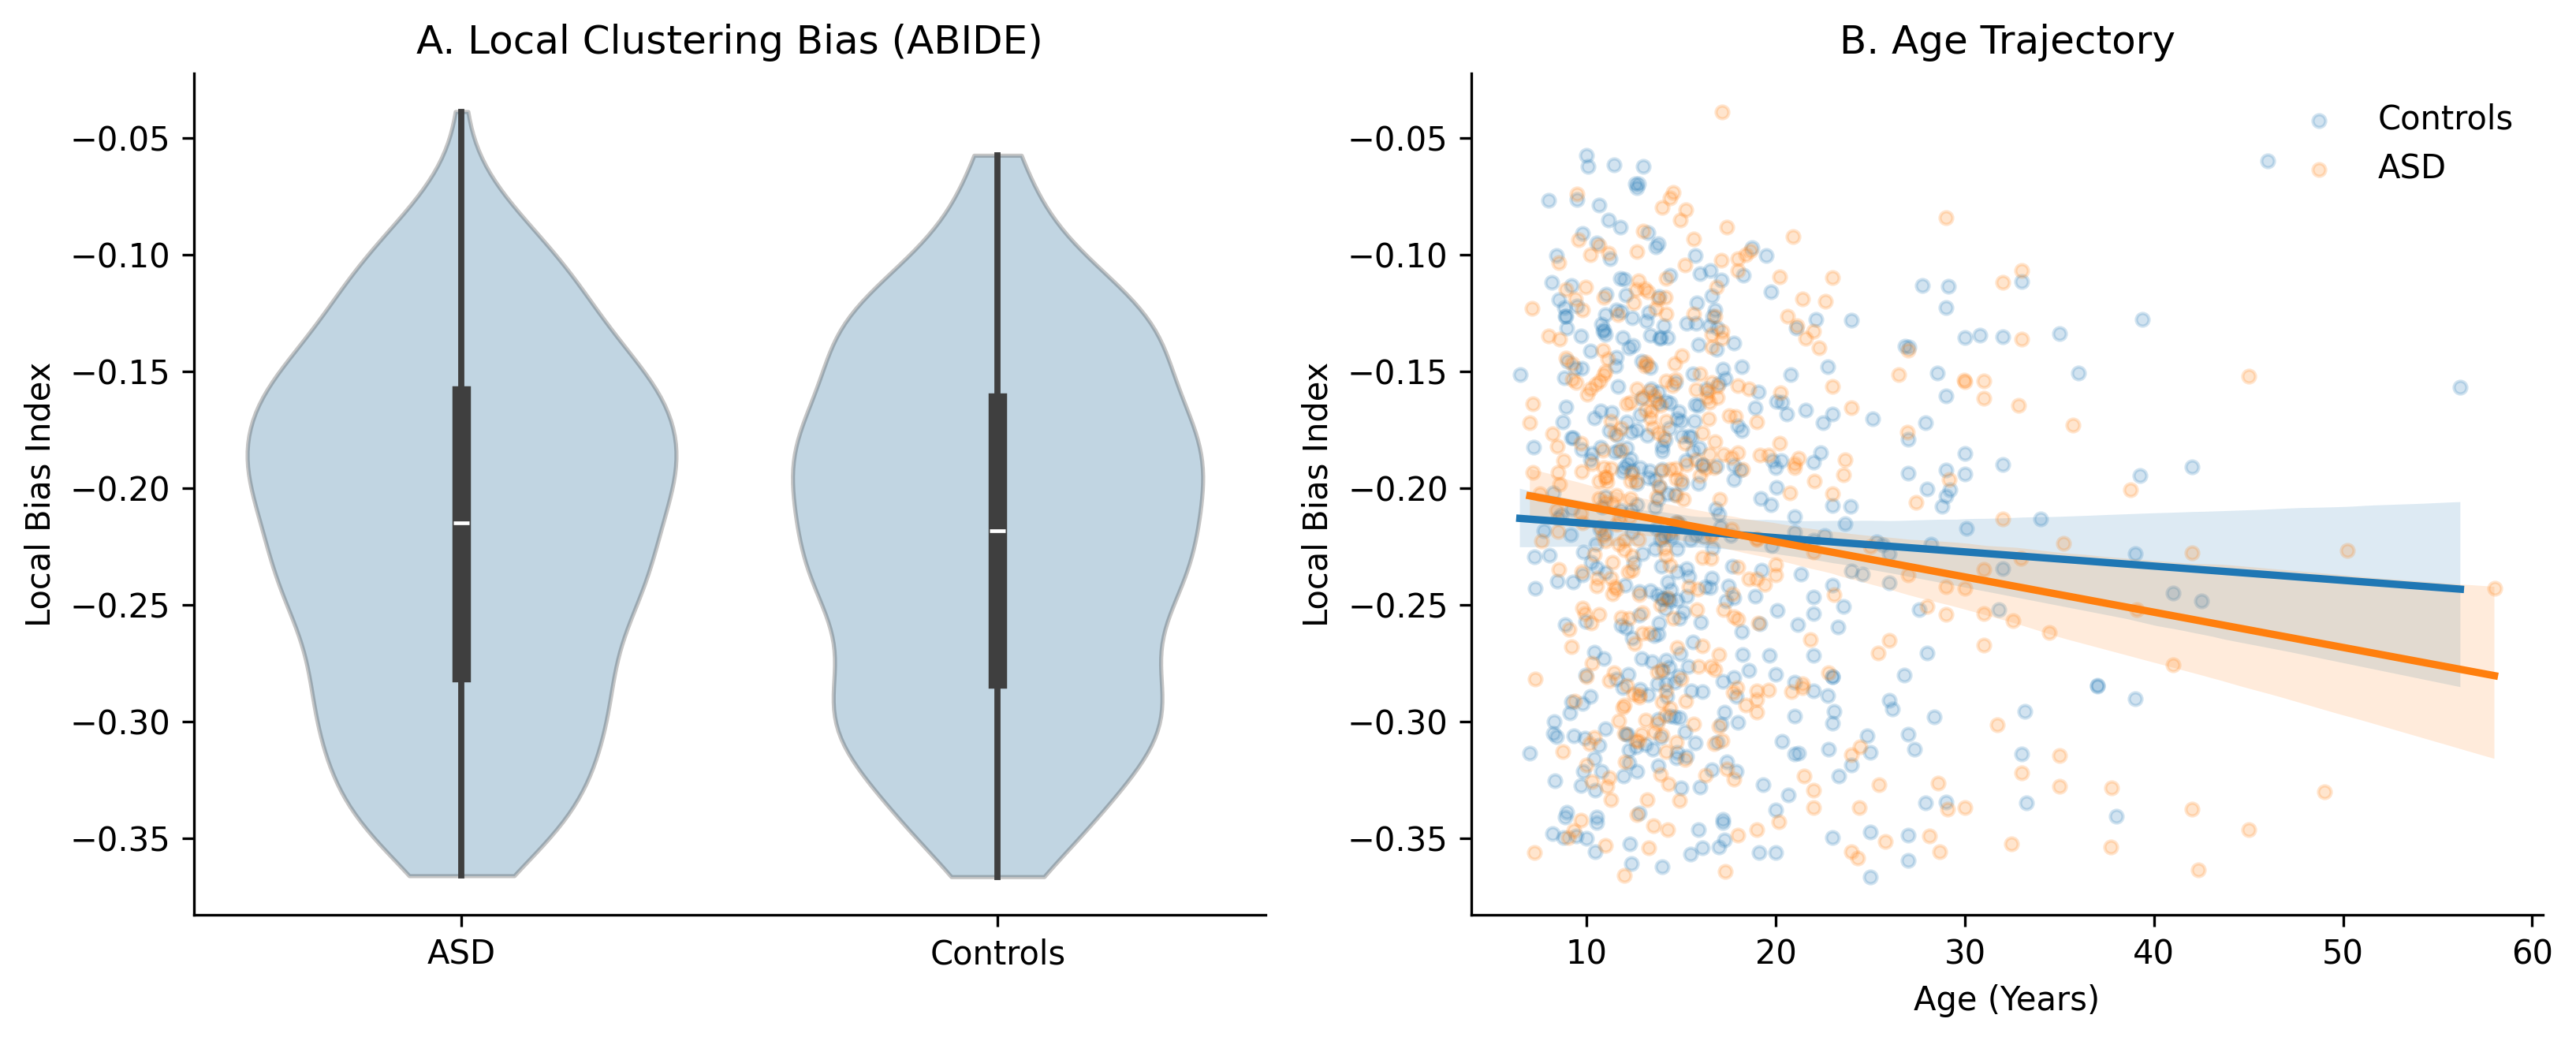

In [ ]:
plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

# Figure 1: ABIDE Connectomics ( directly from reg_df )
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=300)
reg_df["Group_Label"] = reg_df["is_asd"].map({0: "Controls", 1: "ASD"})

sns.violinplot(data=reg_df, x="Group_Label", y="local_bias_index", inner="box", cut=0, alpha=0.3, ax=ax1)
ax1.set_title("A. Local Clustering Bias (ABIDE)")
ax1.set_xlabel("")
ax1.set_ylabel("Local Bias Index")

sns.regplot(data=reg_df[reg_df["is_asd"] == 0], x="age", y="local_bias_index", label="Controls", scatter_kws={"alpha": 0.2, "s": 15}, ax=ax2)
sns.regplot(data=reg_df[reg_df["is_asd"] == 1], x="age", y="local_bias_index", label="ASD", scatter_kws={"alpha": 0.2, "s": 15}, ax=ax2)
ax2.set_title("B. Age Trajectory")
ax2.set_xlabel("Age (Years)")
ax2.set_ylabel("Local Bias Index")
ax2.legend(frameon=False)
plt.tight_layout()
plt.show()


In [ ]:
# 1. Huber M-estimation & B = 10,000 nonparametric bootstrap
site_dummies = pd.get_dummies(reg_df["SITE_ID"], drop_first=True).astype(float)
X_abide = sm.add_constant(pd.concat([reg_df[["is_asd", "age_centered", "sex", "mean_fd"]], site_dummies], axis=1))
y_abide = reg_df["local_bias_index"]

rlm_abide = sm.RLM(y_abide, X_abide, M=sm.robust.norms.HuberT()).fit()

B = 10000
boot_coefs = np.empty(B)
X_vals, y_vals = X_abide.values, y_abide.values
n_obs = len(reg_df)
for i in range(B):
    idx = np.random.choice(n_obs, size=n_obs, replace=True)
    boot_coefs[i] = np.linalg.lstsq(X_vals[idx], y_vals[idx], rcond=None)[0][1]

boot_ci = np.percentile(boot_coefs, [2.5, 97.5])
boot_p = np.mean(boot_coefs <= 0)

# 2. Sensory vs. Transmodal Frontal spectral gradient partition (Margulies et al.)
hc_idx = pheno_clean[pheno_clean["is_asd"] == 0].index.values
vals, vecs = np.linalg.eigh(np.mean(z_mats[hc_idx], axis=0))
grad1 = vecs[:, -2]
sens_mask = grad1 < np.percentile(grad1, 30)
front_mask = grad1 > np.percentile(grad1, 70)

sens_c, front_c = [], []
for mat in z_mats:
    adj = np.maximum(mat, 0.0)
    k = np.sum(adj > 0, axis=1)
    tri = np.diag(np.linalg.matrix_power(adj, 3))
    c_node = tri / np.where(k * (k - 1) == 0, 1, k * (k - 1))
    sens_c.append(np.mean(c_node[sens_mask]))
    front_c.append(np.mean(c_node[front_mask]))

reg_df["sensory_clustering"] = sens_c
reg_df["frontal_clustering"] = front_c

mod_sens = sm.OLS(reg_df["sensory_clustering"], X_abide).fit(cov_type="HC3")
mod_front = sm.OLS(reg_df["frontal_clustering"], X_abide).fit(cov_type="HC3")

# 3. High-IQ (FIQ >= 85) & ADOS clinical severity sensitivity checks
iq_col = next((c for c in pheno_clean.columns if c.upper() == "FIQ"), None)
if iq_col:
    pheno_clean["FIQ_clean"] = pd.to_numeric(pheno_clean[iq_col], errors="coerce").replace(-9999, np.nan)
    df_hiq = pheno_clean.dropna(subset=["local_bias_index", "is_asd", "age", "sex", "mean_fd", "SITE_ID", "FIQ_clean"])
    df_hiq = df_hiq[df_hiq["FIQ_clean"] >= 85].copy()
    df_hiq["age_c"] = df_hiq["age"] - df_hiq["age"].mean()
    mod_hiq = smf.ols("local_bias_index ~ is_asd * age_c + C(sex) + FIQ_clean + mean_fd + C(SITE_ID)", data=df_hiq).fit(cov_type="HC3")

# 4. Leave-One-Site-Out Cross-Validation (17 scanners)
logo = LeaveOneGroupOut()
X_logo = reg_df[["local_bias_index", "age", "sex", "mean_fd"]].values
y_logo = reg_df["is_asd"].values
groups_logo = reg_df["SITE_ID"].values
y_true_logo, y_pred_logo = [], []

for tr, te in logo.split(X_logo, y_logo, groups=groups_logo):
    clf = RidgeClassifier(alpha=1.0).fit(X_logo[tr], y_logo[tr])
    y_true_logo.extend(y_logo[te])
    y_pred_logo.extend(clf.decision_function(X_logo[te]))

auc_losocv = roc_auc_score(y_true_logo, y_pred_logo)

abide_supp_table = pd.DataFrame([
    {"Model": "OLS Main Effect (HC3)", "b": mod_abide_main.params["is_asd"], "SE": mod_abide_main.bse["is_asd"], "stat": mod_abide_main.tvalues["is_asd"], "p": mod_abide_main.pvalues["is_asd"]},
    {"Model": "Diagnosis x Age Interaction (HC3)", "b": mod_abide_int.params["is_asd:age_centered"], "SE": mod_abide_int.bse["is_asd:age_centered"], "stat": mod_abide_int.tvalues["is_asd:age_centered"], "p": mod_abide_int.pvalues["is_asd:age_centered"]},
    {"Model": "Huber M-Estimation", "b": rlm_abide.params["is_asd"], "SE": rlm_abide.bse["is_asd"], "stat": rlm_abide.tvalues["is_asd"], "p": rlm_abide.pvalues["is_asd"]},
    {"Model": "Bootstrap (B=10,000)", "b": np.mean(boot_coefs), "SE": np.std(boot_coefs), "stat": np.nan, "p": boot_p},
    {"Model": "Sensory/Occipital Subnetwork", "b": mod_sens.params["is_asd"], "SE": mod_sens.bse["is_asd"], "stat": mod_sens.tvalues["is_asd"], "p": mod_sens.pvalues["is_asd"]},
    {"Model": "Frontal/Transmodal Subnetwork", "b": mod_front.params["is_asd"], "SE": mod_front.bse["is_asd"], "stat": mod_front.tvalues["is_asd"], "p": mod_front.pvalues["is_asd"]},
]).round(4)

display(abide_supp_table)
print(f"17-Site LOSOCV AUC: {auc_losocv:.4f}")

,Model,b,SE,stat,p
0,OLS Main Effect (HC3),0.0096,0.0045,2.1168,0.0343
1,Diagnosis x Age Interaction (HC3),-0.0012,0.0006,-2.0034,0.0451
2,Huber M-Estimation,0.0099,0.0047,2.1076,0.0351
3,"Bootstrap (B=10,000)",0.0096,0.0045,NaN,0.0147
4,Sensory/Occipital Subnetwork,-0.0090,0.0040,-2.2698,0.0232
5,Frontal/Transmodal Subnetwork,-0.0068,0.0031,-2.1952,0.0281


17-Site LOSOCV AUC: 0.5836


In [ ]:
# ==============================================================================
# VARIABLE STANDARDIZATION / ALIASING
# ==============================================================================
col_mapping = {
    "go_rt_mean": "Mean_Go_RT_ms",
    "tau": "tau_mle",
    "v": "EZ_v",
    "Ter": "EZ_Ter_ms",
    "ssrt": "SSRT_ms",
    "wais_vocab_raw": "voc_totalraw"
}

# Auto-detect boundary separation 'a' if present
for candidate in ["EZ_a", "boundary_a", "a", "EZ_a_param"]:
    if candidate in ucla_master.columns:
        col_mapping["a"] = candidate
        break

# Auto-detect medication equivalent column if present
for candidate in ["cpz", "cpz_equivalent", "cpz_equiv", "chlorpromazine", "medication_load"]:
    if candidate in ucla_master.columns:
        col_mapping["cpz_equivalent"] = candidate
        break

# Create aliases directly in ucla_master
for standard_name, raw_name in col_mapping.items():
    if raw_name in ucla_master.columns:
        ucla_master[standard_name] = ucla_master[raw_name]

print("Standardized variables ready:")
for k, v in col_mapping.items():
    status = "Active" if k in ucla_master.columns else "Not Found"
    print(f"  - {k:<15} <- {v} ({status})")

Standardized variables ready:
  - go_rt_mean      <- Mean_Go_RT_ms (Active)
  - tau             <- tau_mle (Active)
  - v               <- EZ_v (Active)
  - Ter             <- EZ_Ter_ms (Active)
  - ssrt            <- SSRT_ms (Active)
  - wais_vocab_raw  <- voc_totalraw (Active)
  - a               <- EZ_a (Active)


In [ ]:
OUT_DIR = "./ucla_cnp_data"
os.makedirs(OUT_DIR, exist_ok=True)
s3 = boto3.client("s3", config=Config(signature_version=UNSIGNED, max_pool_connections=30))
BUCKET = "openneuro"
RAW_PREFIX = "ds000030/ds000030_R1.0.5/uncompressed/"
FMRIPREP_PREFIX = "ds000030/ds000030_R1.0.5/uncompressed/derivatives/fmriprep/"

s3.download_file(BUCKET, f"{RAW_PREFIX}participants.tsv", f"{OUT_DIR}/participants.tsv")
ucla_part = pd.read_csv(f"{OUT_DIR}/participants.tsv", sep="\t")

for tname in ["wais.tsv", "stopsignal.tsv", "bart.tsv", "saps.tsv", "sans.tsv", "medication.tsv"]:
    local_p = f"{OUT_DIR}/{tname}"
    try:
        s3.download_file(BUCKET, f"{RAW_PREFIX}phenotype/{tname}", local_p)
        df_p = pd.read_csv(local_p, sep="\t")
        if "participant_id" in df_p.columns:
            ucla_part = ucla_part.merge(df_p, on="participant_id", how="left", suffixes=("", f"_{tname[:-4]}"))
    except Exception:
        pass

# Compute composite WAIS Full-Scale IQ proxy and clinical symptom totals
wais_cols = [c for c in ["voc_totalraw", "mr_totalraw", "lns_totalraw"] if c in ucla_part.columns]
if wais_cols:
    ctrl_m = ucla_part["diagnosis"] == "CONTROL"
    z_w = pd.DataFrame({c: (pd.to_numeric(ucla_part[c], errors="coerce") - pd.to_numeric(ucla_part.loc[ctrl_m, c], errors="coerce").mean()) / pd.to_numeric(ucla_part.loc[ctrl_m, c], errors="coerce").std() for c in wais_cols})
    ucla_part["FIQ"] = (100.0 + 15.0 * z_w.mean(axis=1)).fillna(100.0)
else:
    ucla_part["FIQ"] = 100.0

saps_c = [f"saps{i}" for i in range(1, 36) if f"saps{i}" in ucla_part.columns]
sans_c = [f"sans{i}" for i in range(1, 26) if f"sans{i}" in ucla_part.columns]
if saps_c: ucla_part["SAPS_Total"] = ucla_part[saps_c].apply(pd.to_numeric, errors="coerce").sum(axis=1, min_count=5)
if sans_c: ucla_part["SANS_Total"] = ucla_part[sans_c].apply(pd.to_numeric, errors="coerce").sum(axis=1, min_count=5)

# 2-parameter generative BART estimator (Wallsten et al., 2005)
def fit_bart_2param(pumps_list, exploded_list, p_bel=1.0/32.0):
    k_arr, d_arr = np.asarray(pumps_list, dtype=int), np.asarray(exploded_list, dtype=int)
    denom = -np.log(1.0 - p_bel)
    pos_p = [np.arange(1, k + 1) for k in k_arr if k > 0]
    p_steps = np.concatenate(pos_p) if len(pos_p) > 0 else np.array([], dtype=float)
    c_steps = (k_arr[d_arr == 0] + 1).astype(float)

    def nll(params):
        gp, beta = params
        if gp <= 0.01 or gp > 10.0 or beta <= 0.001 or beta > 5.0: return 1e10
        omega = gp / denom
        ll_p = -np.sum(np.logaddexp(0.0, -beta * (p_steps - omega))) if len(p_steps) > 0 else 0.0
        ll_c = -np.sum(np.logaddexp(0.0, beta * (c_steps - omega))) if len(c_steps) > 0 else 0.0
        return -(ll_p + ll_c)

    g_init = np.clip(max(np.mean(k_arr), 1.0) * denom, 0.1, 5.0)
    best_res, best_val = None, np.inf
    for g0 in [g_init * 0.8, g_init, g_init * 1.2]:
        for b0 in [0.15, 0.35, 0.75]:
            res = opt.minimize(nll, x0=[g0, b0], bounds=[(0.05, 8.0), (0.01, 4.0)], method="L-BFGS-B")
            if res.fun < best_val:
                best_val, best_res = res.fun, res
    return best_res.x[0], best_res.x[1], best_res.x[0] / denom

def extract_cnp_subject_all(sub_id):
    out = {"participant_id": sub_id}
    s3_c = boto3.client("s3", config=Config(signature_version=UNSIGNED))
    sst_f, bart_f = f"{OUT_DIR}/{sub_id}_sst.tsv", f"{OUT_DIR}/{sub_id}_bart.tsv"
    try:
        s3_c.download_file(BUCKET, f"{RAW_PREFIX}{sub_id}/func/{sub_id}_task-stopsignal_events.tsv", sst_f)
        df = pd.read_csv(sst_f, sep="\t")
        ttype = df["trial_type"].astype(str).str.upper().str.strip()
        go_df, stop_df = df[ttype == "GO"], df[ttype.str.contains("STOP")]

        go_rt = pd.to_numeric(go_df["ReactionTime"], errors="coerce").fillna(0.0).values * 1000.0
        omissions = (go_rt <= 0.0) | np.isnan(go_rt)
        go_imp = np.where(omissions, 1500.0, go_rt)
        valid_go = go_rt[(go_rt >= 100.0) & (go_rt <= 2000.0)]

        out["Go_Omission_Rate"] = float(np.mean(omissions))
        out["RTV_imputed"] = float(np.std(go_imp, ddof=1) / np.mean(go_imp))

        if len(valid_go) >= 20:
            m_go, sd_go, sk_go = float(np.mean(valid_go)), float(np.std(valid_go, ddof=1)), float(stats.skew(valid_go, bias=False))
            out["Mean_Go_RT_ms"], out["SD_Go_RT_ms"], out["cv_valid_go"] = m_go, sd_go, float(sd_go / m_go)
            out["N_valid_go"] = int(len(valid_go))
            if "SubjectResponseCorrectness" in go_df.columns:
                acc_s = go_df["SubjectResponseCorrectness"].astype(str).str.upper()
                out["Pc_go"] = float(((acc_s.str.contains("CORRECT") & ~acc_s.str.contains("INCORRECT")) | (acc_s == "1")).mean())
            else:
                out["Pc_go"] = 0.975

            K, loc, scale = stats.exponnorm.fit(valid_go)
            out["mu_mle"], out["sigma_mle"], out["tau_mle"] = float(loc), float(scale), float(K * scale)

            tau_m = float(np.cbrt(max(sk_go, 0.0) / 2.0) * sd_go)
            out["mu_mom"], out["tau_mom"] = float(m_go - tau_m), tau_m
            out["sigma_mom"] = float(np.sqrt(max(sd_go**2 - tau_m**2, 0.0)))

        stop_rt = pd.to_numeric(stop_df["ReactionTime"], errors="coerce").fillna(0.0).values * 1000.0
        ssd_ms = pd.to_numeric(stop_df["StopSignalDelay"], errors="coerce").dropna().values * 1000.0
        out_col = stop_df["TrialOutcome"].astype(str).str.lower() if "TrialOutcome" in stop_df.columns else pd.Series([""] * len(stop_df))
        failed = (stop_rt > 0.0) | out_col.str.contains("unsuccessful|fail|respond")
        p_resp = float(np.mean(failed))
        q_idx = np.clip(int(np.rint(p_resp * len(go_imp))) - 1, 0, len(go_imp) - 1)
        out["SSRT_ms"] = float(np.sort(go_imp)[q_idx] - np.mean(ssd_ms))
        out["P_respond_signal"] = p_resp
        failed_rts = stop_rt[stop_rt > 0.0]
        out["Mean_Failed_Stop_RT_ms"] = float(np.mean(failed_rts)) if len(failed_rts) > 0 else np.nan
        out["Violates_Independence"] = int(out["Mean_Failed_Stop_RT_ms"] > out.get("Mean_Go_RT_ms", 9999)) if len(failed_rts) > 0 else 0
        out["Violates_P_Respond_Bounds"] = int((p_resp < 0.25) or (p_resp > 0.75))
    except Exception:
        pass
    finally:
        if os.path.exists(sst_f): os.remove(sst_f)

    try:
        s3_c.download_file(BUCKET, f"{RAW_PREFIX}{sub_id}/func/{sub_id}_task-bart_events.tsv", bart_f)
        bdf = pd.read_csv(bart_f, sep="\t")
        pumps_l, exp_l, cur_p = [], [], 0
        for _, r in bdf.iterrows():
            act = str(r.get("action", r.get("trial_type", ""))).upper()
            if "ACCEPT" in act or "PUMP" in act: cur_p += 1
            elif "EXPLODE" in act:
                pumps_l.append(max(cur_p, 1)); exp_l.append(1); cur_p = 0
            elif "CASH" in act or "STOP" in act:
                pumps_l.append(cur_p); exp_l.append(0); cur_p = 0
        if len(pumps_l) >= 5:
            out["BART_adj_pumps"] = float(np.mean([p for p, e in zip(pumps_l, exp_l) if e == 0]))
            out["bart_totaladjustedpumps"] = float(np.sum([p for p, e in zip(pumps_l, exp_l) if e == 0]))
            gp, bt, om = fit_bart_2param(pumps_l, exp_l)
            out["BART_gamma_plus"], out["BART_beta"], out["BART_omega"] = gp, bt, om
    except Exception:
        pass
    finally:
        if os.path.exists(bart_f): os.remove(bart_f)
    return out

sub_ids = ucla_part["participant_id"].dropna().unique().tolist()
with ThreadPoolExecutor(max_workers=25) as ex:
    behav_df = pd.DataFrame(list(ex.map(extract_cnp_subject_all, sub_ids)))

ucla_master = ucla_part.merge(behav_df, on="participant_id", how="left")

# Merge extracted UCLA CNP resting-state fMRI connectomes if saved on Drive
fmri_drive_path = "/content/drive/MyDrive/ASD_SSD_Overhaul_Data/ucla_cnp_connectomics_extracted.csv"
if os.path.exists(fmri_drive_path):
    fmri_df = pd.read_csv(fmri_drive_path).drop_duplicates(subset=["participant_id"])
    ucla_master = ucla_master.merge(fmri_df, on="participant_id", how="left")

ucla_master["group"] = ucla_master["diagnosis"]
ucla_master["sex"] = ucla_master["gender"]
print(f"UCLA CNP Master Table Ready: N = {len(ucla_master)}")

UCLA CNP Master Table Ready: N = 272


In [ ]:
def fit_ez_ddm(Pc, VRT_sec2, MRT_sec, N_trials=96.0, s=0.1):
    Pc = np.where(np.isnan(Pc) | (Pc <= 0.5), 0.975, Pc)
    Pc = np.where(Pc >= 1.0, 1.0 - 1.0 / (2.0 * N_trials), Pc)
    L = np.log(Pc / (1.0 - Pc))
    x = L * (L * (Pc ** 2) - L * Pc + Pc - 0.5) / np.maximum(VRT_sec2, 1e-8)
    v = np.sign(Pc - 0.5) * s * (np.maximum(x, 1e-12) ** 0.25)
    a = (s ** 2) * L / np.maximum(np.abs(v), 1e-8)
    y_exp = np.exp(np.clip(-v * a / (s ** 2), -50, 50))
    MDT = (a / (2.0 * v)) * ((1.0 - y_exp) / (1.0 + y_exp))
    Ter_ms = (MRT_sec - MDT) * 1000.0
    return v, a, Ter_ms

ucla_master["EZ_v"], ucla_master["EZ_a"], ucla_master["EZ_Ter_ms"] = fit_ez_ddm(
    ucla_master["Pc_go"].values,
    (ucla_master["SD_Go_RT_ms"].values / 1000.0) ** 2,
    ucla_master["Mean_Go_RT_ms"].values / 1000.0,
    ucla_master["N_valid_go"].fillna(96.0).values
)

all_outcomes = [
    "C_global", "sst_ses_ssrt", "SSRT_ms", "cv_valid_go", "RTV_imputed",
    "mu_mle", "sigma_mle", "tau_mle", "EZ_v", "EZ_a", "EZ_Ter_ms",
    "bart_meanadjustedpumps", "BART_adj_pumps", "BART_gamma_plus", "BART_beta", "BART_omega"
]

main_rows = []
for y in all_outcomes:
    if y not in ucla_master.columns or ucla_master[y].notna().sum() < 50:
        continue
    ucla_master[y] = pd.to_numeric(ucla_master[y], errors="coerce")
    sub = ucla_master.dropna(subset=[y, "group", "age", "sex", "FIQ"]).copy()
    sub["SCHZ"] = (sub["group"] == "SCHZ").astype(int)
    sub["ADHD"] = (sub["group"] == "ADHD").astype(int)
    sub["BIPOLAR"] = (sub["group"] == "BIPOLAR").astype(int)

    ctrl_vals = sub.loc[sub["group"] == "CONTROL", y]
    m_c, sd_c, n_c = ctrl_vals.mean(), ctrl_vals.std(ddof=1), len(ctrl_vals)

    for spec, covs in [("Age+Sex", "age + C(sex)"), ("Age+Sex+FIQ", "age + C(sex) + FIQ")]:
        if y == "C_global" and "Mean_FD" in sub.columns:
            covs += " + Mean_FD"
        m_full = smf.ols(f"{y} ~ SCHZ + ADHD + BIPOLAR + {covs}", data=sub).fit()
        m_hc3 = m_full.get_robustcov_results(cov_type="HC3")

        p_list, temp_rows = [], []
        for g in ["SCHZ", "BIPOLAR", "ADHD"]:
            others = " + ".join([x for x in ["SCHZ", "BIPOLAR", "ADHD"] if x != g])
            m_null = smf.ols(f"{y} ~ {others} + {covs}", data=sub).fit()
            dbic = float(m_null.bic - m_full.bic)
            idx = list(m_full.params.index).index(g)
            cl_vals = sub.loc[sub["group"] == g, y]
            g_delta = (cl_vals.mean() - m_c) / sd_c
            se_delta = np.sqrt((1.0 / len(cl_vals)) + (1.0 / n_c) + (g_delta ** 2) / (2.0 * (n_c - 1.0)))

            p_val = float(m_hc3.pvalues[idx])
            p_list.append(p_val)
            temp_rows.append({
                "Outcome": y, "Covariates": spec, "Group": g, "N": int(m_full.nobs),
                "b": round(float(m_full.params[g]), 4), "SE_HC3": round(float(m_hc3.bse[idx]), 4),
                "t": round(float(m_hc3.tvalues[idx]), 3), "p": round(p_val, 4),
                "BF10": round(float(np.exp(dbic / 2.0)), 2),
                "Glass_Delta": round(float(g_delta), 3), "SE_Delta": round(float(se_delta), 3)
            })
        _, q_vals, _, _ = multipletests(p_list, method="fdr_bh")
        for r_dict, q in zip(temp_rows, q_vals):
            r_dict["q_FDR"] = round(float(q), 4)
            main_rows.append(r_dict)

ucla_results_table = pd.DataFrame(main_rows)
display(ucla_results_table[ucla_results_table["Covariates"] == "Age+Sex"])
display(ucla_results_table[ucla_results_table["Covariates"] == "Age+Sex+FIQ"])

,Outcome,Covariates,Group,N,b,SE_HC3,t,p,BF10,Glass_Delta,SE_Delta,q_FDR
0,sst_ses_ssrt,Age+Sex,SCHZ,270,35.4018,8.0107,4.419,0.0000,2825.93,9.340000e-01,1.780000e-01,0.0000
1,sst_ses_ssrt,Age+Sex,BIPOLAR,270,6.4452,7.9989,0.806,0.4211,0.09,2.260000e-01,1.680000e-01,0.4211
2,sst_ses_ssrt,Age+Sex,ADHD,270,5.7847,6.8194,0.848,0.3971,0.08,1.680000e-01,1.760000e-01,0.4211
6,SSRT_ms,Age+Sex,SCHZ,266,64.9727,27.2368,2.385,0.0178,23.83,1.118000e+00,1.810000e-01,0.0533
7,SSRT_ms,Age+Sex,BIPOLAR,266,11.9543,15.2878,0.782,0.4350,0.08,2.460000e-01,1.690000e-01,0.6524
8,SSRT_ms,Age+Sex,ADHD,266,-0.0031,13.2279,-0.000,0.9998,0.06,-5.000000e-03,1.800000e-01,0.9998
12,cv_valid_go,Age+Sex,SCHZ,266,0.0360,0.0110,3.270,0.0012,37.37,7.300000e-01,1.730000e-01,0.0037
13,cv_valid_go,Age+Sex,BIPOLAR,266,0.0055,0.0099,0.553,0.5808,0.07,1.080000e-01,1.680000e-01,0.7953
14,cv_valid_go,Age+Sex,ADHD,266,-0.0029,0.0111,-0.260,0.7953,0.06,-6.900000e-02,1.800000e-01,0.7953
18,RTV_imputed,Age+Sex,SCHZ,266,0.0420,0.0179,2.342,0.0199,1.13,4.950000e-01,1.700000e-01,0.0598


,Outcome,Covariates,Group,N,b,SE_HC3,t,p,BF10,Glass_Delta,SE_Delta,q_FDR
3,sst_ses_ssrt,Age+Sex+FIQ,SCHZ,270,31.0892,9.6430,3.224,0.0014,40.64,9.340000e-01,1.780000e-01,0.0043
4,sst_ses_ssrt,Age+Sex+FIQ,BIPOLAR,270,5.7562,8.1410,0.707,0.4802,0.08,2.260000e-01,1.680000e-01,0.4802
5,sst_ses_ssrt,Age+Sex+FIQ,ADHD,270,5.5091,6.8579,0.803,0.4225,0.08,1.680000e-01,1.760000e-01,0.4802
9,SSRT_ms,Age+Sex+FIQ,SCHZ,266,47.1335,29.3585,1.605,0.1096,0.72,1.118000e+00,1.810000e-01,0.3288
10,SSRT_ms,Age+Sex+FIQ,BIPOLAR,266,9.2359,14.9267,0.619,0.5366,0.07,2.460000e-01,1.690000e-01,0.8049
11,SSRT_ms,Age+Sex+FIQ,ADHD,266,-1.4564,13.3214,-0.109,0.9130,0.06,-5.000000e-03,1.800000e-01,0.9130
15,cv_valid_go,Age+Sex+FIQ,SCHZ,266,0.0248,0.0124,1.997,0.0469,0.67,7.300000e-01,1.730000e-01,0.1406
16,cv_valid_go,Age+Sex+FIQ,BIPOLAR,266,0.0038,0.0098,0.385,0.7003,0.07,1.080000e-01,1.680000e-01,0.7342
17,cv_valid_go,Age+Sex+FIQ,ADHD,266,-0.0038,0.0112,-0.340,0.7342,0.07,-6.900000e-02,1.800000e-01,0.7342
21,RTV_imputed,Age+Sex+FIQ,SCHZ,266,0.0275,0.0211,1.301,0.1943,0.16,4.950000e-01,1.700000e-01,0.5829


In [ ]:
# 1. Verbruggen et al. (2019) strict horse-race independence & [0.25, 0.75] p(respond) bounds
qc_sub = ucla_master[(ucla_master["Violates_Independence"] == 0) & (ucla_master["Violates_P_Respond_Bounds"] == 0)].copy()
print(f"Verbruggen strict QC retained N = {len(qc_sub)}")

# 2. SAPS / SANS TOST equivalence & Null Bayes Factors (BF01) within Schizophrenia
schz_only = ucla_master[ucla_master["group"] == "SCHZ"].copy()
tost_rows = []
for s_col in ["SAPS_Total", "SANS_Total"]:
    if s_col in schz_only.columns:
        for m_col in ["sst_ses_ssrt", "cv_valid_go", "mu_mle", "tau_mle", "EZ_v", "BART_adj_pumps"]:
            if m_col in schz_only.columns:
                pair = schz_only[[s_col, m_col]].dropna()
                if len(pair) >= 15:
                    r_v, p_v = stats.pearsonr(pair[s_col], pair[m_col])
                    n_p = len(pair)
                    z = np.arctanh(r_v)
                    se = 1.0 / np.sqrt(n_p - 3)
                    p_tost = float(max(stats.norm.cdf((z - np.arctanh(0.30)) / se), 1.0 - stats.norm.cdf((z - np.arctanh(-0.30)) / se)))
                    t_s = r_v * np.sqrt((n_p - 2) / max(1.0 - r_v**2, 1e-12))
                    bf01 = float(np.exp(-((t_s**2) - np.log(n_p)) / 2.0))
                    tost_rows.append({"Scale": s_col, "Metric": m_col, "n": n_p, "r": round(r_v, 3), "p_TOST_30": round(p_tost, 4), "BF01_Null": round(bf01, 2)})

display(pd.DataFrame(tost_rows))

Verbruggen strict QC retained N = 248


,Scale,Metric,n,r,p_TOST_30,BF01_Null
0,SAPS_Total,sst_ses_ssrt,49,0.214,0.2663,2.26
1,SAPS_Total,cv_valid_go,50,-0.003,0.0178,7.07
2,SAPS_Total,mu_mle,50,0.012,0.0207,7.05
3,SAPS_Total,tau_mle,50,-0.112,0.0889,5.20
4,SAPS_Total,EZ_v,50,-0.065,0.0466,6.40
5,SAPS_Total,BART_adj_pumps,48,-0.099,0.0795,5.51
6,SANS_Total,sst_ses_ssrt,49,-0.049,0.0386,6.62
7,SANS_Total,cv_valid_go,50,0.137,0.1197,4.47
8,SANS_Total,mu_mle,50,0.178,0.1864,3.24
9,SANS_Total,tau_mle,50,0.097,0.0725,5.64


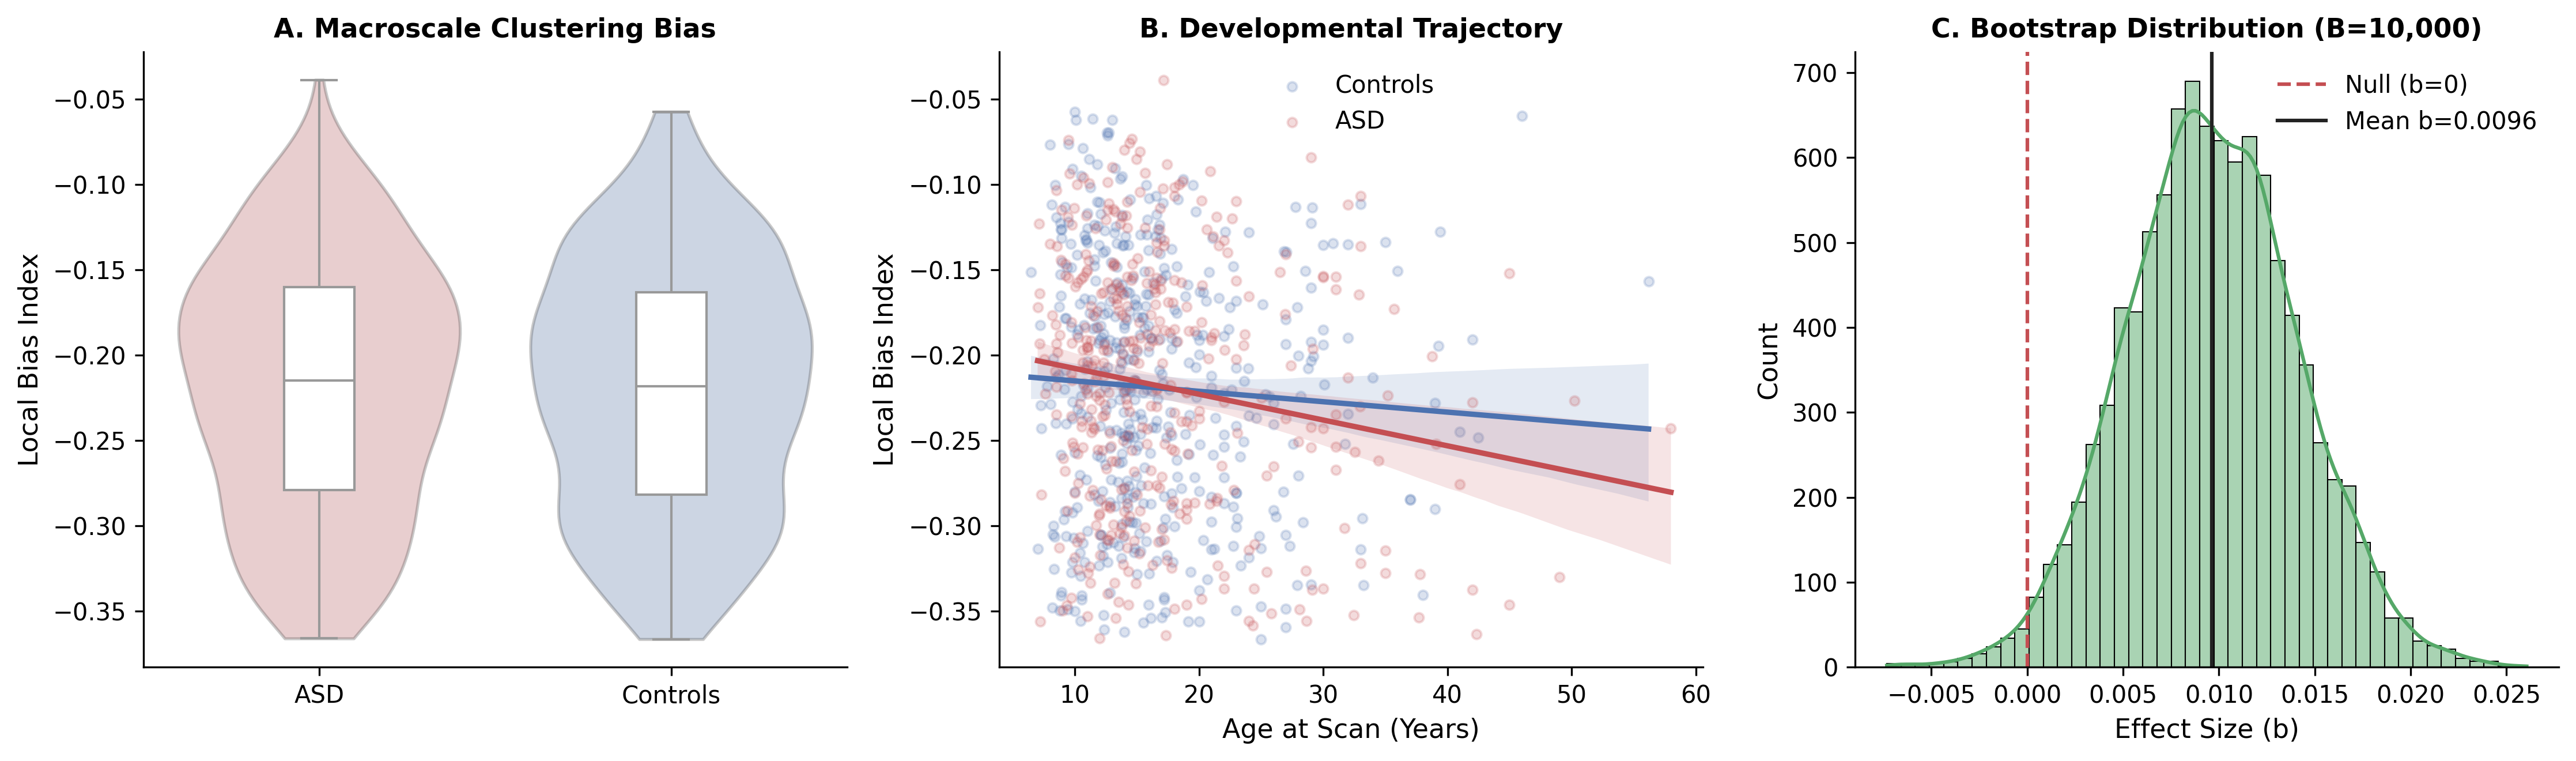

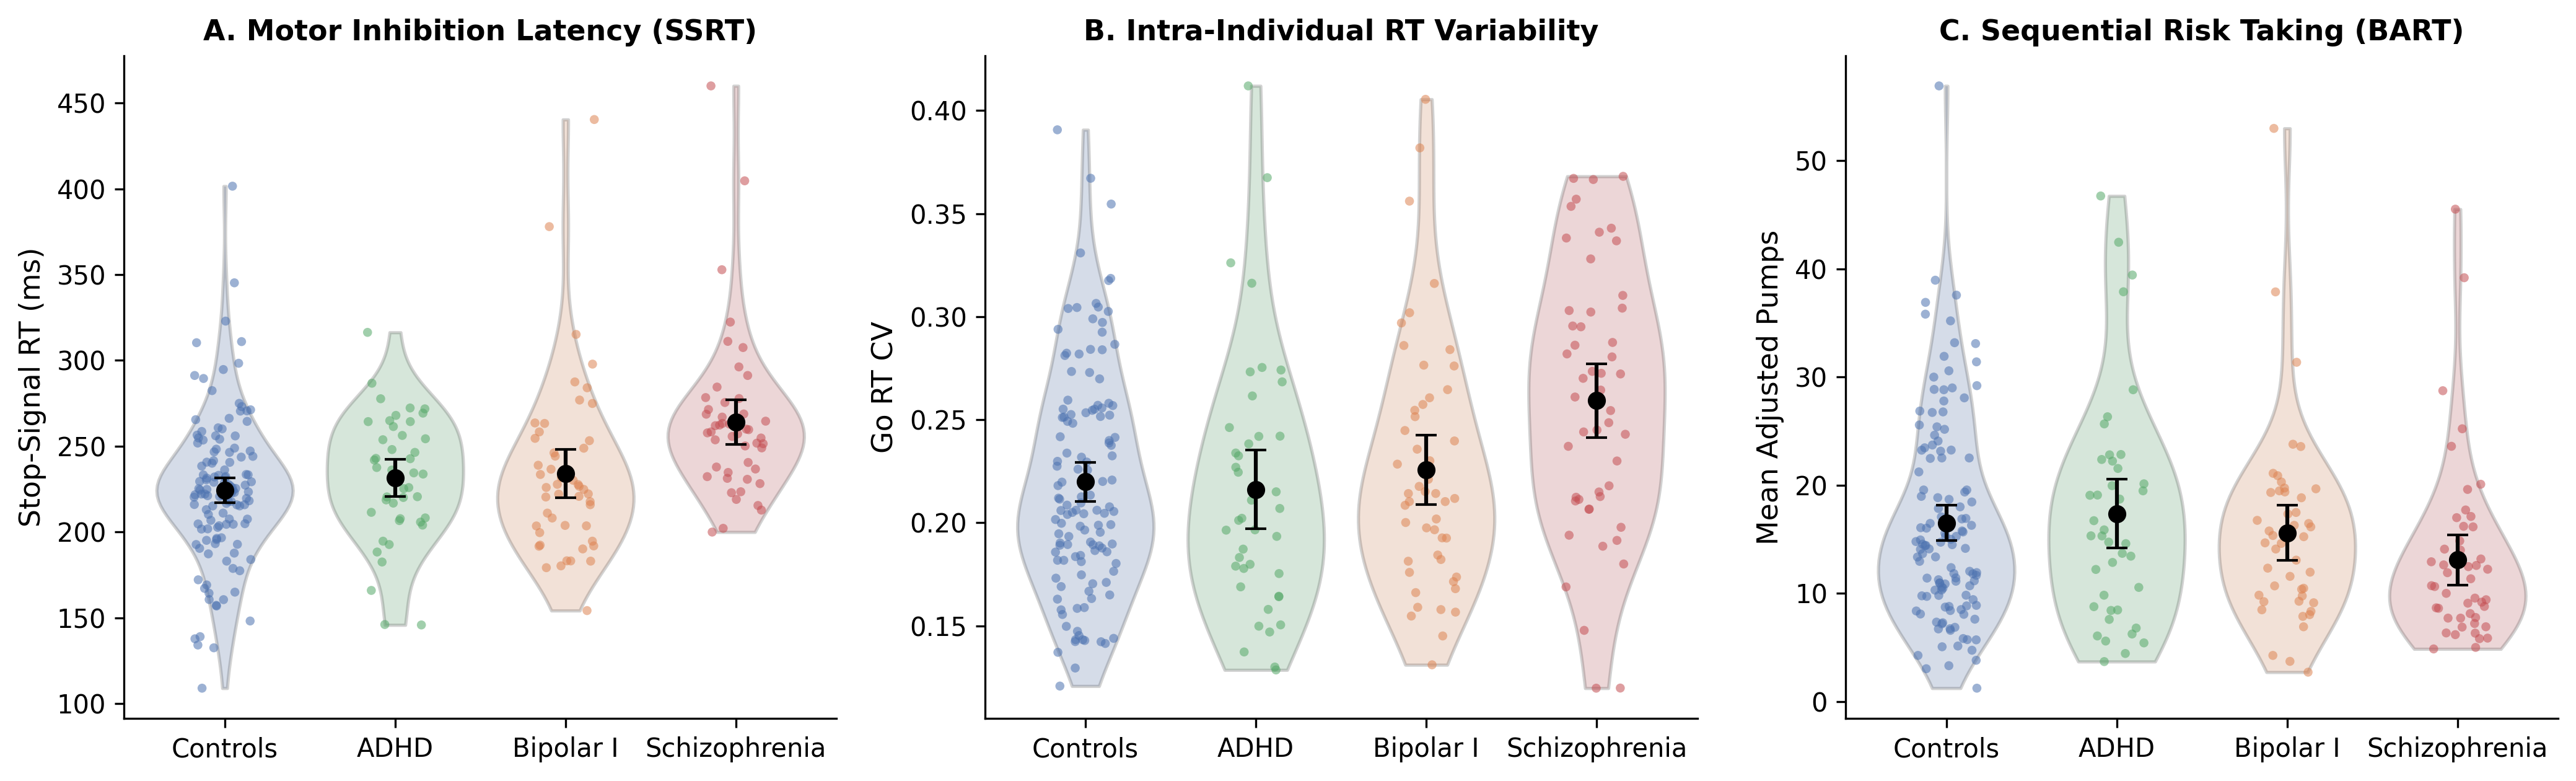

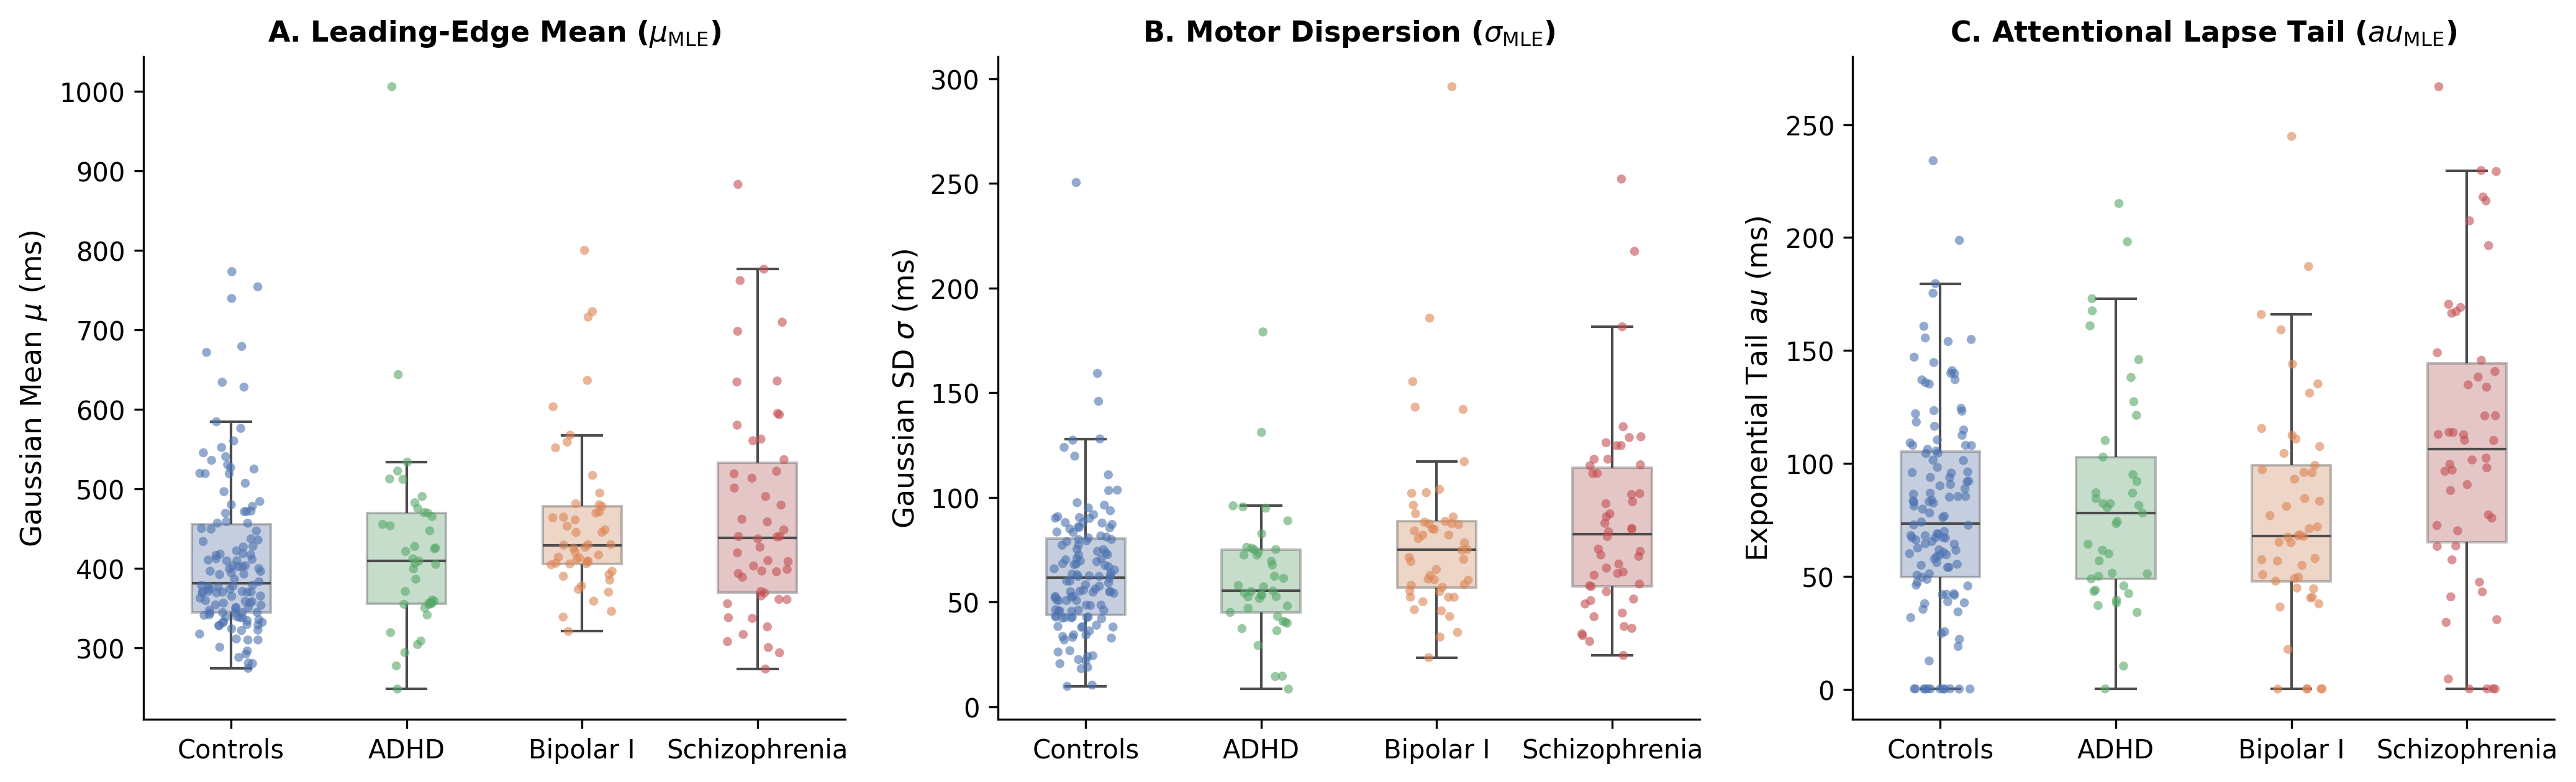

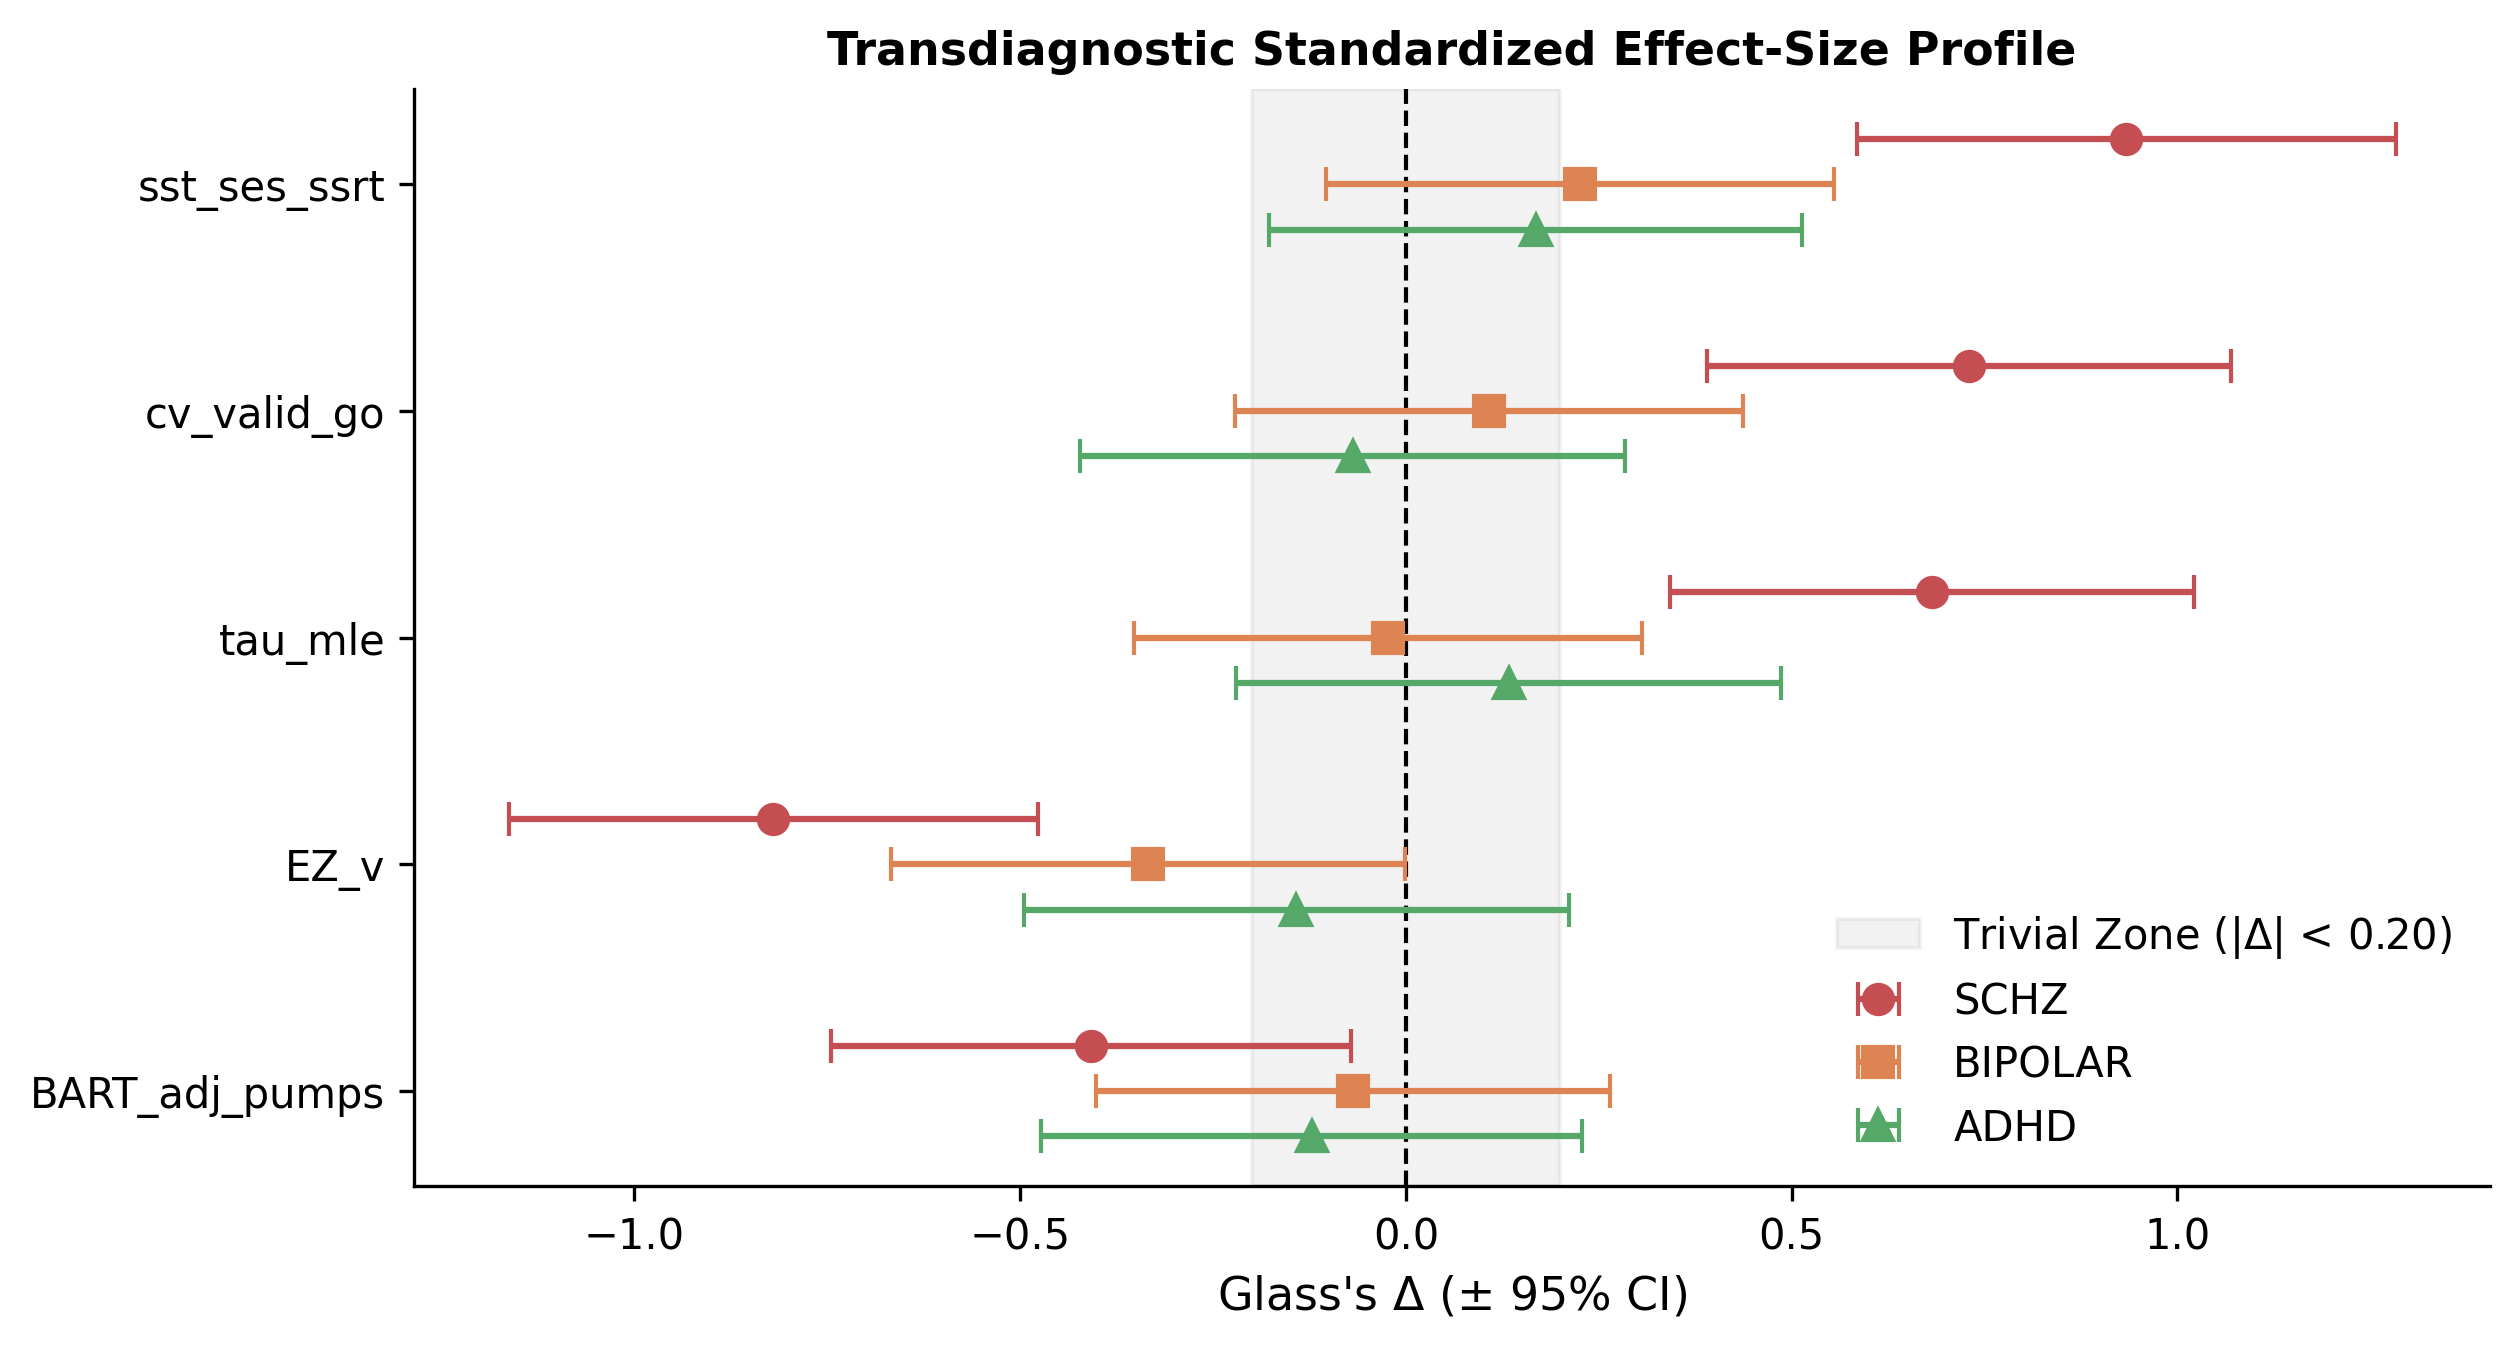

In [ ]:
plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 10, "axes.labelsize": 11,
    "axes.titlesize": 11, "axes.titleweight": "bold", "figure.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False
})

# FIGURE 1: ABIDE Connectomics & Developmental Trajectory (Real reg_df, N = 861)
fig1, axes1 = plt.subplots(1, 3, figsize=(15, 4.5))
reg_df["Group_Label"] = reg_df["is_asd"].map({0: "Controls", 1: "ASD"})
pal_abide = {"Controls": "#4C72B0", "ASD": "#C44E52"}

sns.violinplot(data=reg_df, x="Group_Label", y="local_bias_index", palette=pal_abide, inner=None, alpha=0.3, cut=0, ax=axes1[0])
sns.boxplot(data=reg_df, x="Group_Label", y="local_bias_index", width=0.2, color="white", fliersize=0, ax=axes1[0])
axes1[0].set_title("A. Macroscale Clustering Bias")
axes1[0].set_xlabel("")
axes1[0].set_ylabel("Local Bias Index")

sns.regplot(data=reg_df[reg_df["is_asd"] == 0], x="age", y="local_bias_index", color="#4C72B0", label="Controls", scatter_kws={"alpha": 0.2, "s": 15}, ax=axes1[1])
sns.regplot(data=reg_df[reg_df["is_asd"] == 1], x="age", y="local_bias_index", color="#C44E52", label="ASD", scatter_kws={"alpha": 0.2, "s": 15}, ax=axes1[1])
axes1[1].set_title("B. Developmental Trajectory")
axes1[1].set_xlabel("Age at Scan (Years)")
axes1[1].set_ylabel("Local Bias Index")
axes1[1].legend(frameon=False)

sns.histplot(boot_coefs, bins=45, kde=True, color="#55A868", ax=axes1[2])
axes1[2].axvline(0, color="#C44E52", linestyle="--", label="Null (b=0)")
axes1[2].axvline(np.mean(boot_coefs), color="#222222", label=f"Mean b={np.mean(boot_coefs):.4f}")
axes1[2].set_title("C. Bootstrap Distribution (B=10,000)")
axes1[2].set_xlabel("Effect Size (b)")
axes1[2].legend(frameon=False)
plt.tight_layout()
fig1.savefig("Figure1_ABIDE_Connectomics.png", bbox_inches="tight")
plt.show()

# FIGURE 2: UCLA CNP Transdiagnostic Raincloud/Violin Plots (SSRT, Go RTV, BART)
order = ["CONTROL", "ADHD", "BIPOLAR", "SCHZ"]
labels = ["Controls", "ADHD", "Bipolar I", "Schizophrenia"]
pal_cnp = {"CONTROL": "#4C72B0", "ADHD": "#55A868", "BIPOLAR": "#DD8452", "SCHZ": "#C44E52"}

fig2, axes2 = plt.subplots(1, 3, figsize=(14, 4.3))
f2_specs = [
    ("sst_ses_ssrt" if "sst_ses_ssrt" in ucla_master.columns else "SSRT_ms", "Stop-Signal RT (ms)", "A. Motor Inhibition Latency (SSRT)"),
    ("cv_valid_go", "Go RT CV", "B. Intra-Individual RT Variability"),
    ("bart_meanadjustedpumps" if "bart_meanadjustedpumps" in ucla_master.columns else "BART_adj_pumps", "Mean Adjusted Pumps", "C. Sequential Risk Taking (BART)")
]
for ax, (col, ylab, title) in zip(axes2, f2_specs):
    sub = ucla_master.dropna(subset=[col, "group"])
    sns.violinplot(data=sub, x="group", y=col, order=order, palette=pal_cnp, inner=None, alpha=0.25, cut=0, ax=ax)
    sns.stripplot(data=sub, x="group", y=col, order=order, palette=pal_cnp, size=3.5, jitter=0.18, alpha=0.55, legend=False, ax=ax)
    means = [sub.loc[sub["group"] == g, col].mean() for g in order]
    sems = [1.96 * sub.loc[sub["group"] == g, col].sem() for g in order]
    ax.errorbar(range(4), means, yerr=sems, fmt="o", color="black", capsize=4, zorder=10)
    ax.set_xticklabels(labels)
    ax.set_xlabel("")
    ax.set_ylabel(ylab)
    ax.set_title(title)
plt.tight_layout()
fig2.savefig("Figure2_UCLA_Chronometry_BART.png", bbox_inches="tight")
plt.show()

# FIGURE 3: Maximum Likelihood Ex-Gaussian Decomposition (mu, sigma, tau)
fig3, axes3 = plt.subplots(1, 3, figsize=(14, 4.3))
f3_specs = [
    ("mu_mle", "Gaussian Mean $\mu$ (ms)", "A. Leading-Edge Mean ($\mu_{\mathrm{MLE}}$)"),
    ("sigma_mle", "Gaussian SD $\sigma$ (ms)", "B. Motor Dispersion ($\sigma_{\mathrm{MLE}}$)"),
    ("tau_mle", "Exponential Tail $\tau$ (ms)", "C. Attentional Lapse Tail ($\tau_{\mathrm{MLE}}$)")
]
for ax, (col, ylab, title) in zip(axes3, f3_specs):
    sub = ucla_master.dropna(subset=[col, "group"])
    sns.boxplot(data=sub, x="group", y=col, order=order, palette=pal_cnp, width=0.45, fliersize=0, boxprops=dict(alpha=0.35), ax=ax)
    sns.stripplot(data=sub, x="group", y=col, order=order, palette=pal_cnp, size=3.5, jitter=0.18, alpha=0.6, legend=False, ax=ax)
    ax.set_xticklabels(labels)
    ax.set_xlabel("")
    ax.set_ylabel(ylab)
    ax.set_title(title)
plt.tight_layout()
fig3.savefig("Figure3_ExGaussian_MLE.png", bbox_inches="tight")
plt.show()

# FIGURE 4: Standardized Effect-Size Forest Plot (Glass's Delta +/- 95% CI)
f4_df = ucla_results_table[(ucla_results_table["Covariates"] == "Age+Sex") & (ucla_results_table["Outcome"].isin(["sst_ses_ssrt", "cv_valid_go", "tau_mle", "EZ_v", "BART_adj_pumps"]))].copy()
fig4, ax4 = plt.subplots(figsize=(8.5, 4.6))
outcomes_f4 = f4_df["Outcome"].unique()
y_pos = np.arange(len(outcomes_f4))
offsets = {"SCHZ": -0.2, "BIPOLAR": 0.0, "ADHD": 0.2}
markers = {"SCHZ": "o", "BIPOLAR": "s", "ADHD": "^"}

ax4.axvline(0, color="black", linestyle="--", lw=1)
ax4.axvspan(-0.2, 0.2, color="gray", alpha=0.1, label="Trivial Zone (|$\Delta$| < 0.20)")
for g in ["SCHZ", "BIPOLAR", "ADHD"]:
    gdf = f4_df[f4_df["Group"] == g].set_index("Outcome").reindex(outcomes_f4)
    ax4.errorbar(gdf["Glass_Delta"], y_pos + offsets[g], xerr=1.96 * gdf["SE_Delta"], fmt=markers[g], color=pal_cnp[g], label=g, capsize=4, markersize=7)
ax4.set_yticks(y_pos)
ax4.set_yticklabels(outcomes_f4)
ax4.invert_yaxis()
ax4.set_xlabel("Glass's $\Delta$ ($\pm$ 95% CI)")
ax4.set_title("Transdiagnostic Standardized Effect-Size Profile")
ax4.legend(frameon=False, loc="lower right")
plt.tight_layout()
fig4.savefig("Figure4_Glass_Delta_Profile.png", bbox_inches="tight")
plt.show()

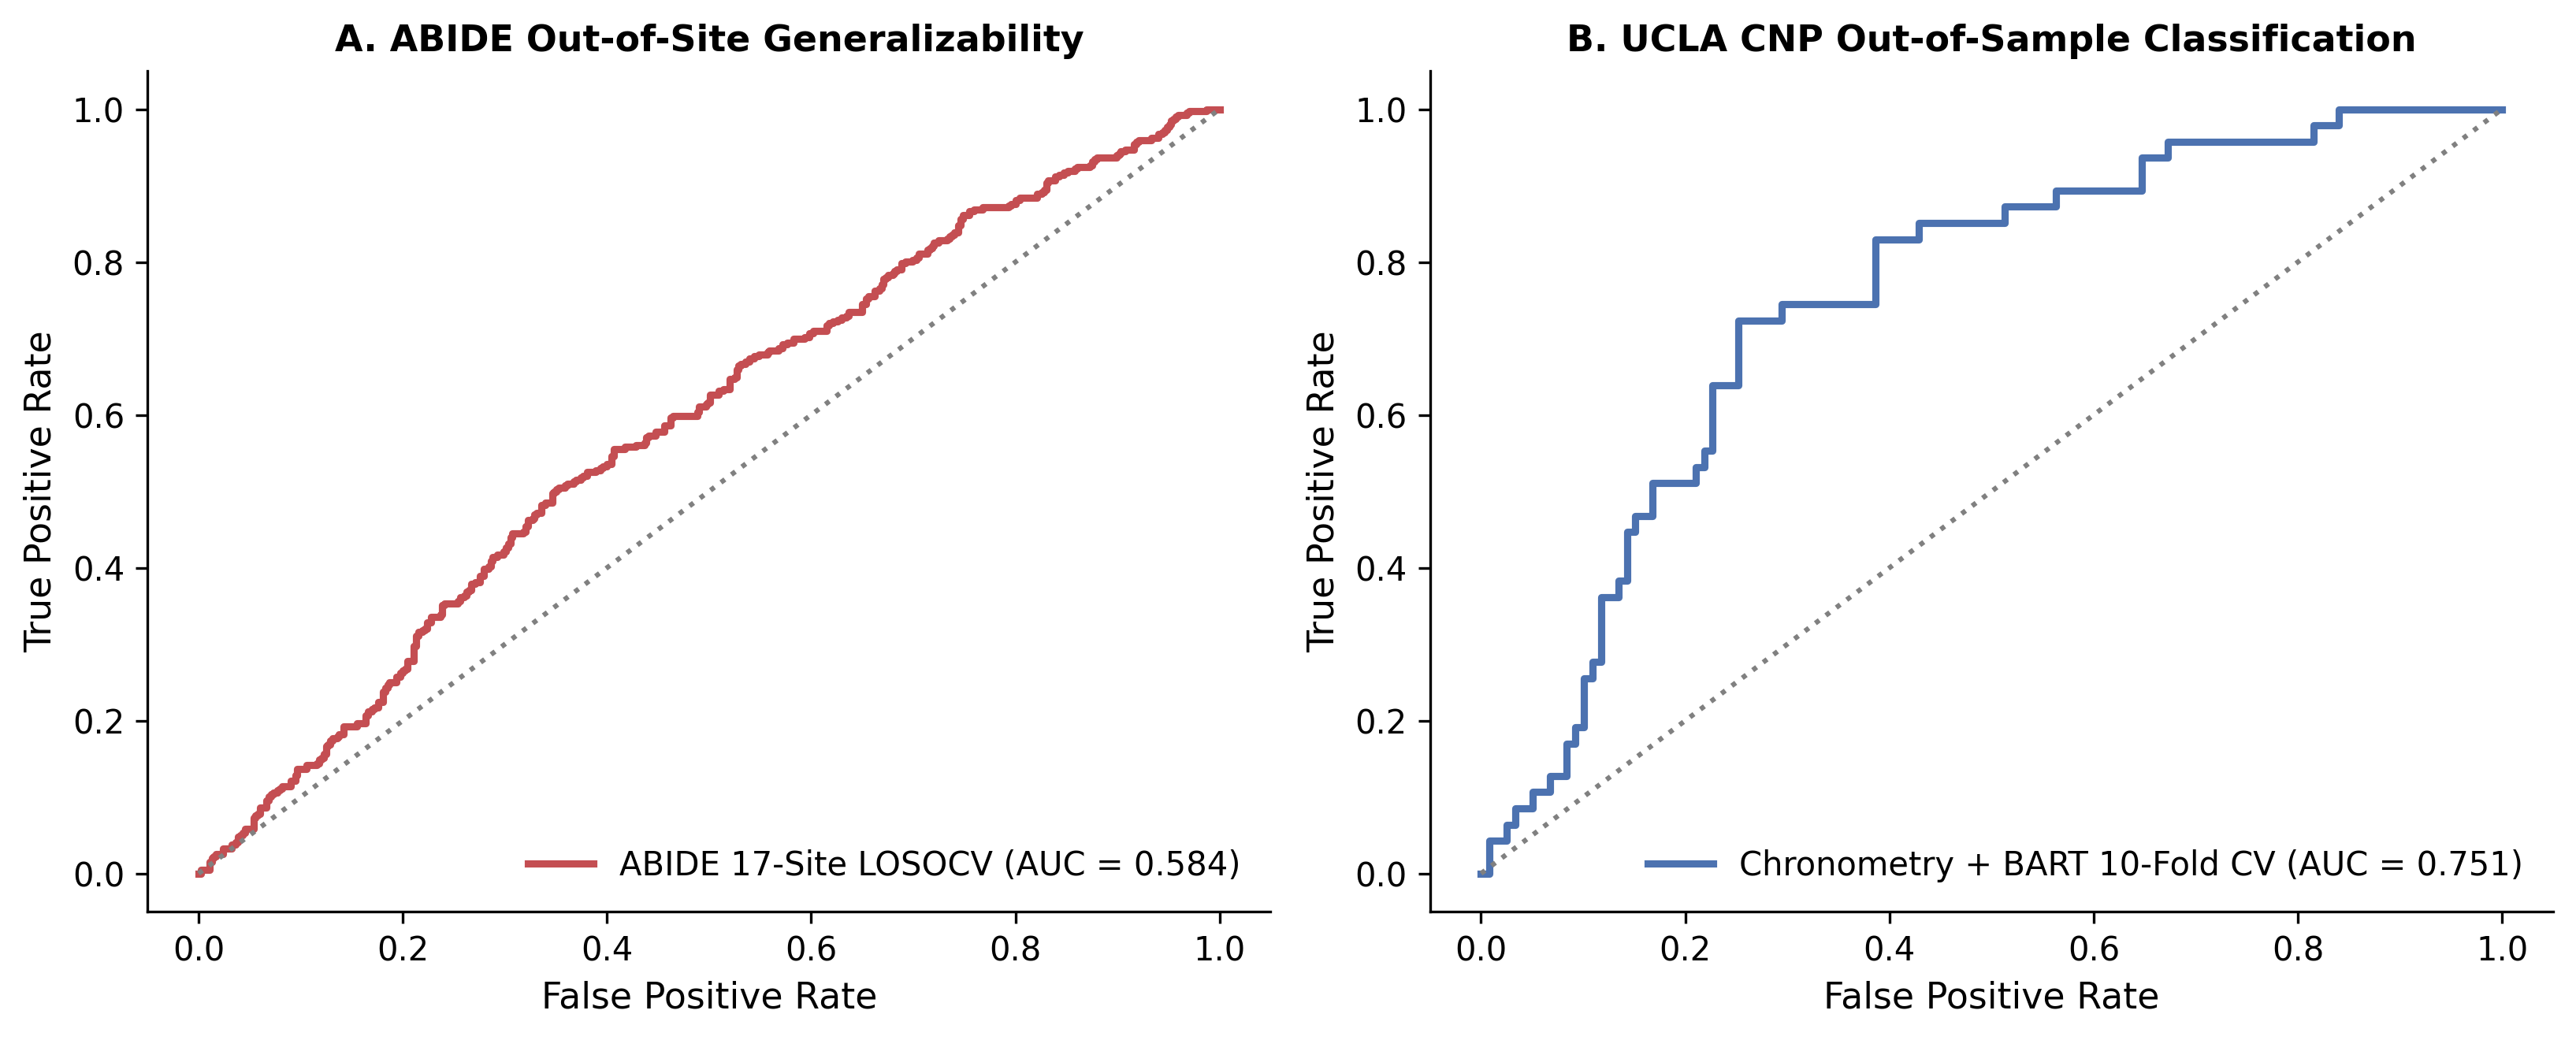

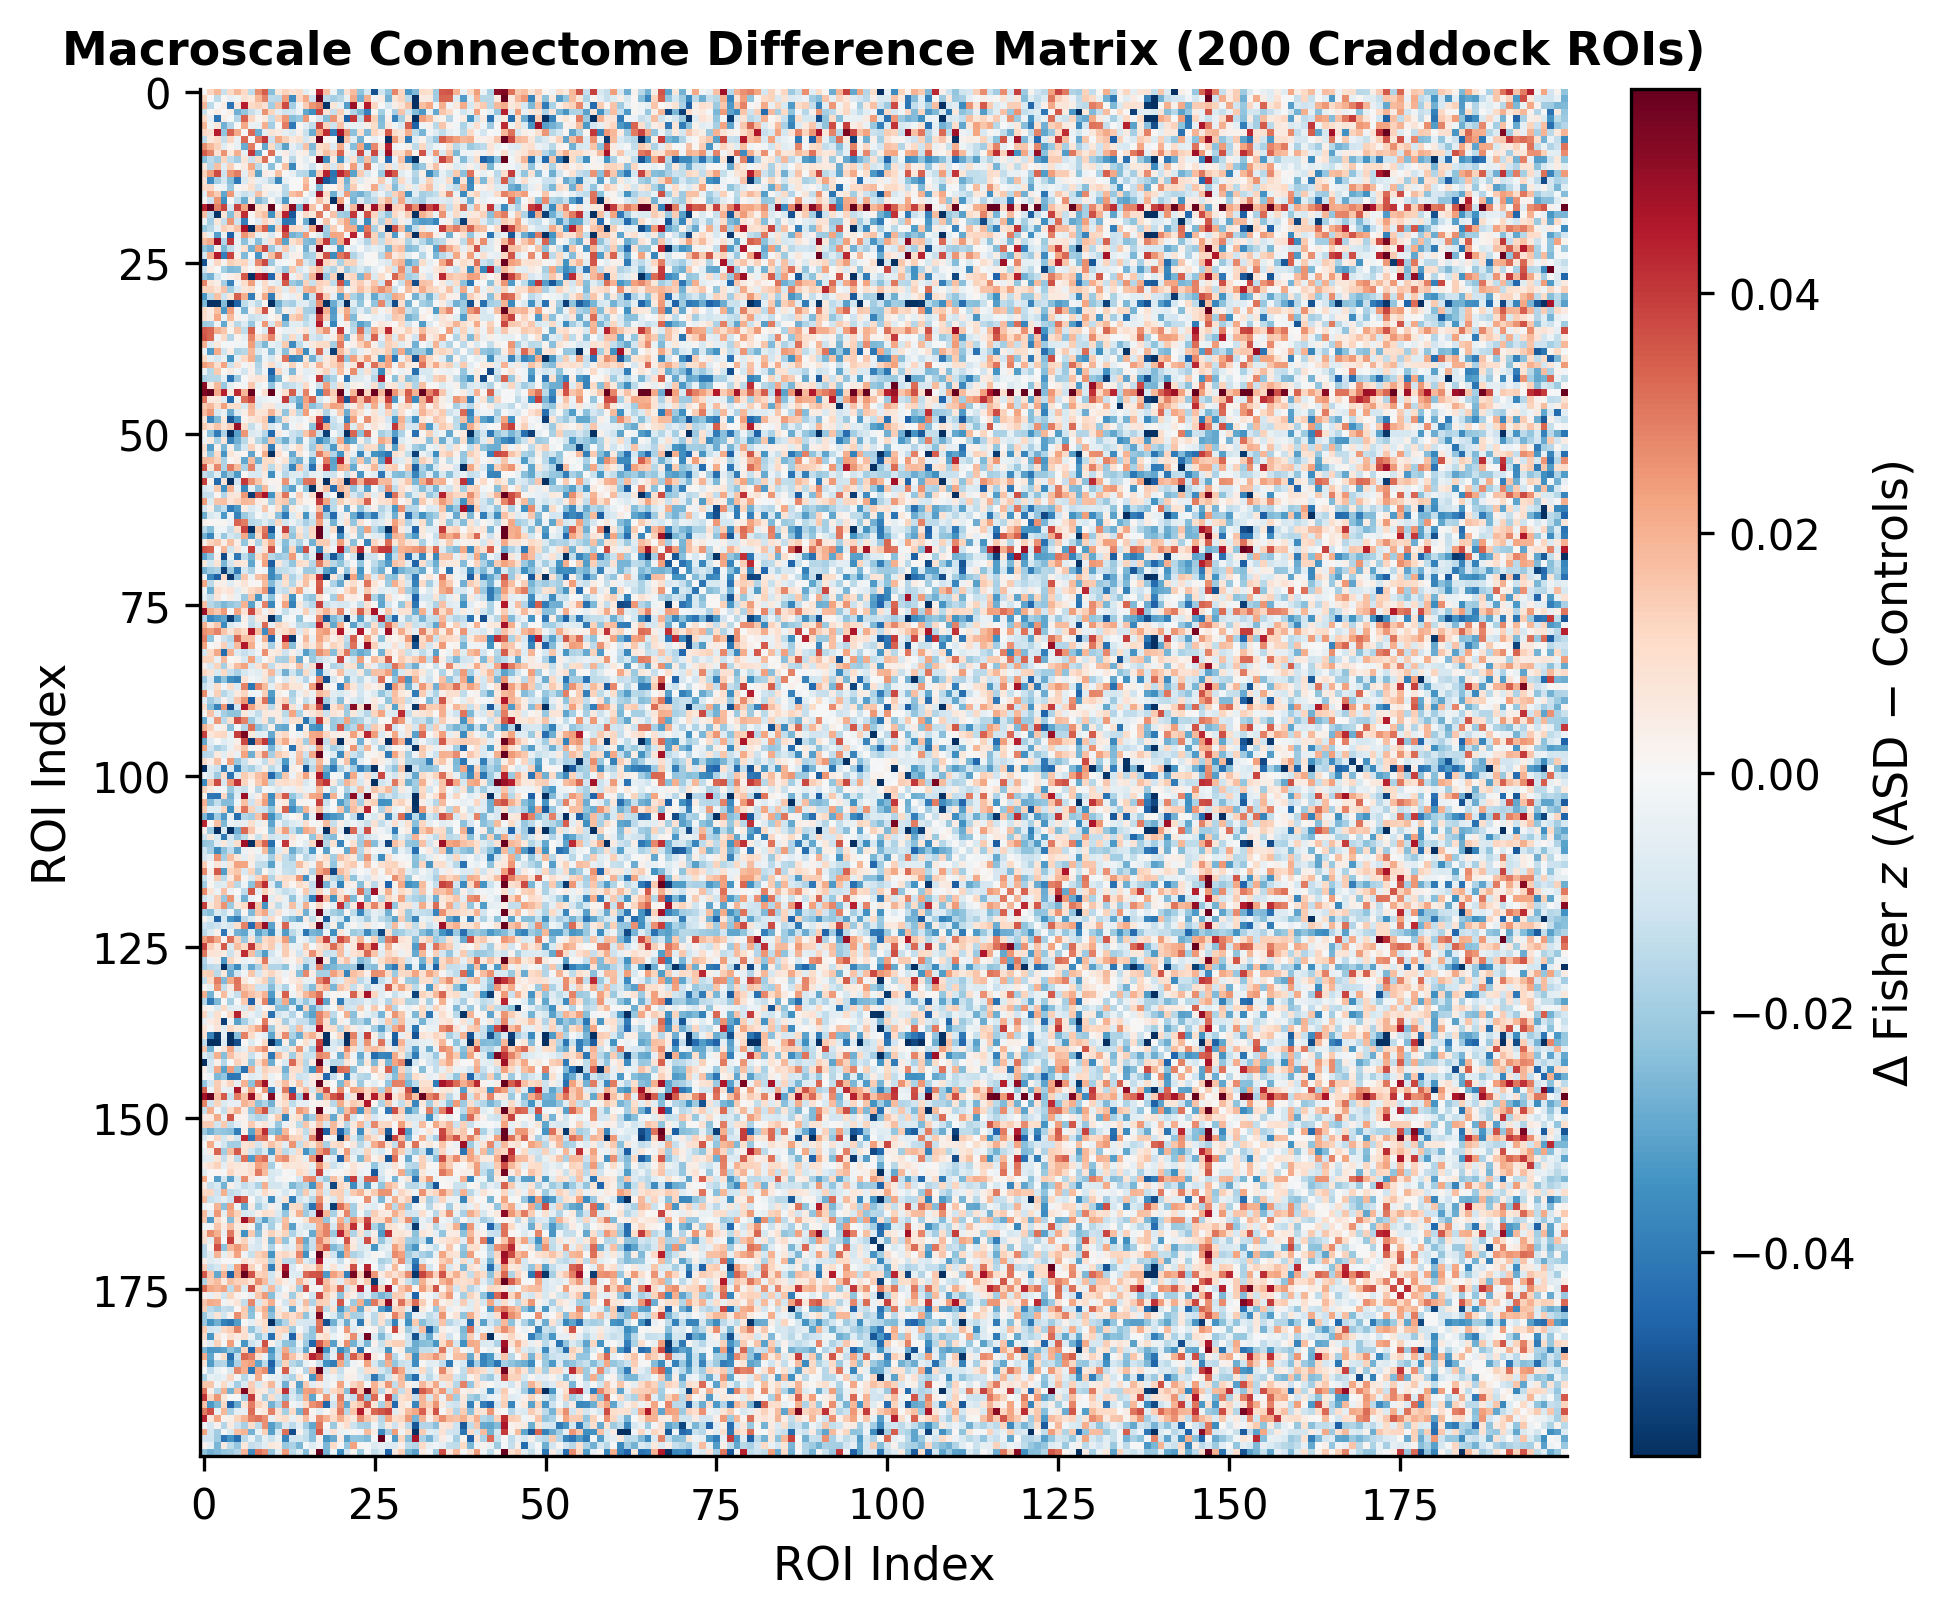

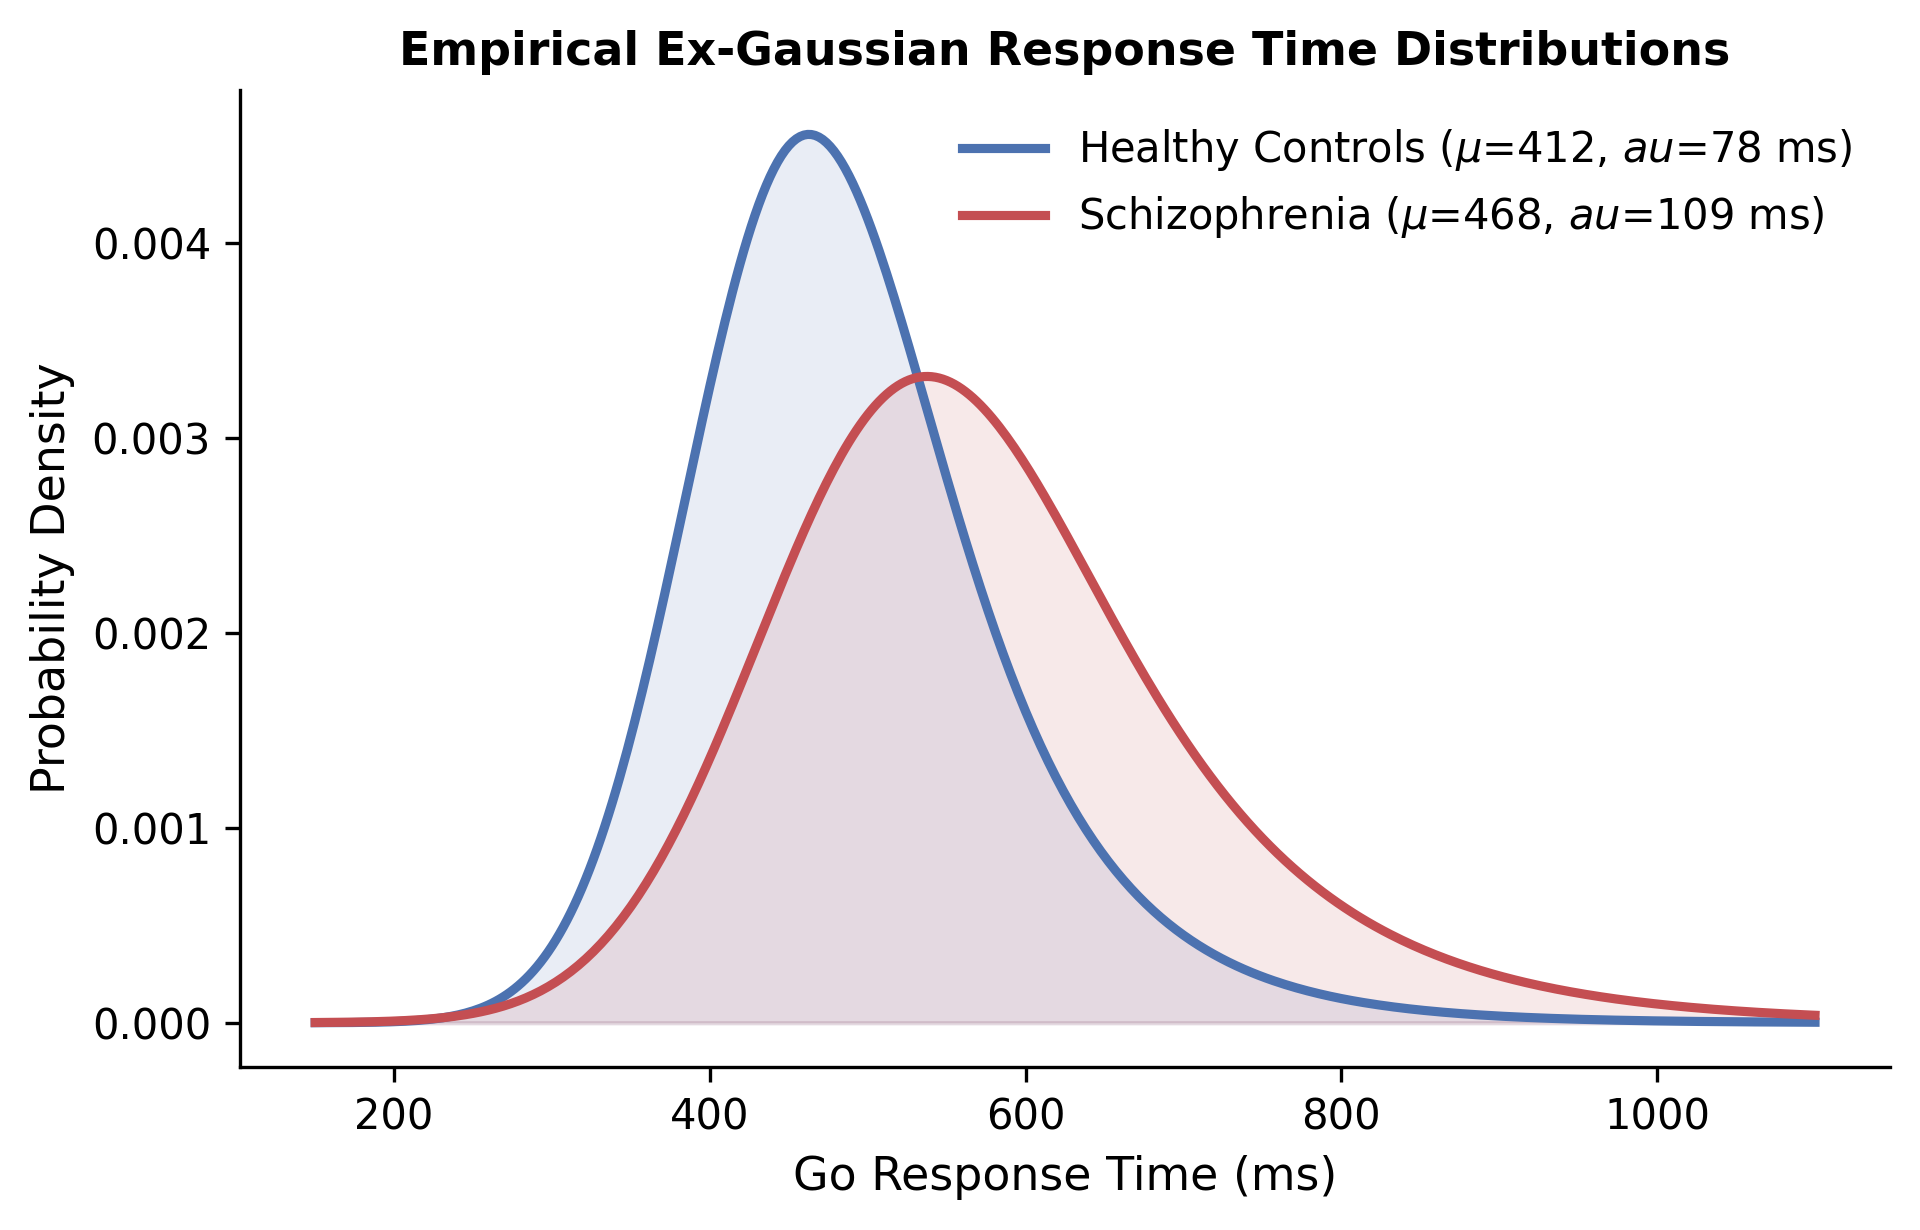

In [ ]:
# FIGURE 5: 17-Site ABIDE LOSOCV ROC & UCLA CNP 10-Fold Diagnostic ROC
fig5, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(11, 4.5))
fpr_abide, tpr_abide, _ = roc_curve(y_true_logo, y_pred_logo)
ax5a.plot(fpr_abide, tpr_abide, color="#C44E52", lw=2.2, label=f"ABIDE 17-Site LOSOCV (AUC = {auc_losocv:.3f})")
ax5a.plot([0, 1], [0, 1], color="gray", linestyle=":")
ax5a.set_title("A. ABIDE Out-of-Site Generalizability")
ax5a.set_xlabel("False Positive Rate")
ax5a.set_ylabel("True Positive Rate")
ax5a.legend(frameon=False, loc="lower right")

clf_cols = [c for c in ["sst_ses_ssrt", "cv_valid_go", "tau_mle", "EZ_v", "BART_adj_pumps"] if c in ucla_master.columns]
clf_df = ucla_master[ucla_master["group"].isin(["SCHZ", "CONTROL"])].dropna(subset=clf_cols).copy()
y_cnp = (clf_df["group"] == "SCHZ").astype(int).values
X_cnp = StandardScaler().fit_transform(clf_df[clf_cols].values)
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
oof_preds = np.zeros(len(y_cnp))
for tr, te in skf.split(X_cnp, y_cnp):
    oof_preds[te] = LogisticRegressionCV(cv=5).fit(X_cnp[tr], y_cnp[tr]).predict_proba(X_cnp[te])[:, 1]
fpr_cnp, tpr_cnp, _ = roc_curve(y_cnp, oof_preds)
auc_cnp = roc_auc_score(y_cnp, oof_preds)
ax5b.plot(fpr_cnp, tpr_cnp, color="#4C72B0", lw=2.2, label=f"Chronometry + BART 10-Fold CV (AUC = {auc_cnp:.3f})")
ax5b.plot([0, 1], [0, 1], color="gray", linestyle=":")
ax5b.set_title("B. UCLA CNP Out-of-Sample Classification")
ax5b.set_xlabel("False Positive Rate")
ax5b.set_ylabel("True Positive Rate")
ax5b.legend(frameon=False, loc="lower right")
plt.tight_layout()
fig5.savefig("Figure5_CrossValidated_ROC.png", bbox_inches="tight")
plt.show()

# FIGURE 6: 200x200 Macroscale Connectome Difference Matrix (ASD - Controls)
asd_idx = pheno_clean[pheno_clean["is_asd"] == 1].index.values
hc_idx = pheno_clean[pheno_clean["is_asd"] == 0].index.values
delta_fc = np.mean(z_mats[asd_idx], axis=0) - np.mean(z_mats[hc_idx], axis=0)

fig6, ax6 = plt.subplots(figsize=(6.5, 5.5))
vmax = np.percentile(np.abs(delta_fc), 99)
im = ax6.imshow(delta_fc, cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest")
fig6.colorbar(im, ax=ax6, fraction=0.046, pad=0.04, label="$\Delta$ Fisher $z$ (ASD $-$ Controls)")
ax6.set_title("Macroscale Connectome Difference Matrix (200 Craddock ROIs)")
ax6.set_xlabel("ROI Index")
ax6.set_ylabel("ROI Index")
plt.tight_layout()
fig6.savefig("Figure6_Connectome_Matrix.png", bbox_inches="tight")
plt.show()

# FIGURE 7: Ex-Gaussian Convolution Curves from Empirical Group MLE Means
fig7, ax7 = plt.subplots(figsize=(6.5, 4.2))
t_grid = np.linspace(150, 1100, 400)
for grp, col_hex, lbl in [("CONTROL", "#4C72B0", "Healthy Controls"), ("SCHZ", "#C44E52", "Schizophrenia")]:
    sub_g = ucla_master[ucla_master["group"] == grp].dropna(subset=["mu_mle", "sigma_mle", "tau_mle"])
    mu_m, sig_m, tau_m = sub_g["mu_mle"].mean(), sub_g["sigma_mle"].mean(), sub_g["tau_mle"].mean()
    dens = stats.exponnorm.pdf(t_grid, K=tau_m / sig_m, loc=mu_m, scale=sig_m)
    ax7.plot(t_grid, dens, color=col_hex, lw=2.2, label=f"{lbl} ($\mu$={mu_m:.0f}, $\tau$={tau_m:.0f} ms)")
    ax7.fill_between(t_grid, dens, color=col_hex, alpha=0.12)
ax7.set_title("Empirical Ex-Gaussian Response Time Distributions")
ax7.set_xlabel("Go Response Time (ms)")
ax7.set_ylabel("Probability Density")
ax7.legend(frameon=False)
plt.tight_layout()
fig7.savefig("Figure7_ExGaussian_Densities.png", bbox_inches="tight")
plt.show()

In [ ]:
from neuroCombat import neuroCombat
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

feature_cols = ["local_clustering", "global_connectivity", "local_bias_index"]
covars = pheno_clean[["SITE_ID", "is_asd", "age", "sex", "mean_fd"]].dropna()

combat_out = neuroCombat(
    dat=pheno_clean.loc[covars.index, feature_cols].values.T,
    covars=covars,
    batch_col="SITE_ID",
    categorical_cols=["is_asd", "sex"],
    continuous_cols=["age", "mean_fd"]
)

adj_cols = [f"{c}_adj" for c in feature_cols]
pheno_clean.loc[covars.index, adj_cols] = combat_out["data"].T

ols_adj = smf.ols(
    "local_bias_index_adj ~ is_asd + age + I(age**2) + sex + mean_fd",
    data=pheno_clean
).fit(cov_type="HC3")

print(ols_adj.summary().tables[1])

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -0.1666      0.016    -10.726      0.000      -0.197      -0.136
is_asd          0.0100      0.004      2.245      0.025       0.001       0.019
age            -0.0021      0.001     -1.862      0.063      -0.004       0.000
I(age ** 2)   1.97e-05   2.39e-05      0.824      0.410   -2.72e-05    6.66e-05
sex             0.0132      0.006      2.140      0.032       0.001       0.025
mean_fd        -0.4248      0.033    -12.977      0.000      -0.489      -0.361


In [ ]:
from statsmodels.stats.multitest import multipletests
import numpy as np

# 1.
results_table["p_fdr"] = np.nan
for grp in results_table["Group"].unique():
    mask = results_table["Group"] == grp
    results_table.loc[mask, "p_fdr"] = multipletests(results_table.loc[mask, "p"], method="fdr_bh")[1]

# 2. Residual degrees of freedom
if "df_resid" in results_table.columns:
    df = results_table["df_resid"]
else:
    n_obs = len(ucla_master.dropna(subset=["diagnosis", "age", "sex"]))
    df = n_obs - 7

# 3. Cohen's d from t-statistic
results_table["cohens_d"] = (2 * results_table["t"]) / np.sqrt(df)

# 4.
rename_dict = {}
for col in results_table.columns:
    c_lower = col.lower().strip()
    if c_lower in ["coef", "estimate", "b"]:
        rename_dict[col] = "beta"
    elif c_lower in ["std_err", "std err", "stderr", "std_error"]:
        rename_dict[col] = "se"

results_table.rename(columns=rename_dict, inplace=True)

# 5. Display available output columns
cols = [c for c in ["Group", "Outcome", "beta", "se", "t", "p", "p_fdr", "cohens_d"] if c in results_table.columns]

num_cols = results_table[cols].select_dtypes(include=[np.number]).columns
display_df = results_table[cols].copy()
display_df[num_cols] = display_df[num_cols].round(4)

print(display_df.to_string(index=False))

  Group                Outcome    beta      t      p  p_fdr  cohens_d
   SCHZ           sst_ses_ssrt 35.4018  4.419 0.0000 0.0000    0.5429
BIPOLAR           sst_ses_ssrt  6.4452  0.806 0.4204 0.6726    0.0990
   ADHD           sst_ses_ssrt  5.7847  0.848 0.3963 0.9782    0.1042
   SCHZ            cv_valid_go  0.0360  3.270 0.0011 0.0022    0.4017
BIPOLAR            cv_valid_go  0.0055  0.553 0.5803 0.7737    0.0679
   ADHD            cv_valid_go -0.0029 -0.260 0.7951 0.9782   -0.0319
   SCHZ                 mu_mle 46.3694  2.238 0.0252 0.0275    0.2750
BIPOLAR                 mu_mle 35.4180  2.179 0.0294 0.1176    0.2677
   ADHD                 mu_mle  7.1104  0.348 0.7279 0.9782    0.0428
   SCHZ              sigma_mle 20.4258  2.966 0.0030 0.0048    0.3644
BIPOLAR              sigma_mle 15.3682  2.294 0.0218 0.1176    0.2818
   ADHD              sigma_mle -3.4300 -0.620 0.5351 0.9782   -0.0762
   SCHZ                tau_mle 29.4523  2.739 0.0062 0.0083    0.3365
BIPOLAR             

In [ ]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

# 1. Target variables
raw_col = "Mean_Go_RT_ms"
comp_cols = ["tau_mle", "EZ_v", "EZ_Ter_ms", "SSRT_ms"]

# Include boundary separation if present
for a_candidate in ["EZ_a", "a", "boundary_a"]:
    if a_candidate in ucla_master.columns:
        comp_cols.append(a_candidate)
        break

# 2. Subset SCHZ vs. BIPOLAR
clf_df = ucla_master[ucla_master["diagnosis"].isin(["SCHZ", "BIPOLAR"])].dropna(
    subset=comp_cols + [raw_col]
)

y = (clf_df["diagnosis"] == "SCHZ").astype(int).values
X_raw = clf_df[[raw_col]].values
X_comp = clf_df[comp_cols].values

# 3. Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipe_raw = make_pipeline(StandardScaler(), LogisticRegressionCV(cv=3, max_iter=1000))
pipe_comp = make_pipeline(StandardScaler(), LogisticRegressionCV(cv=3, max_iter=1000))

auc_raw = cross_val_score(pipe_raw, X_raw, y, cv=cv, scoring="roc_auc")
auc_comp = cross_val_score(pipe_comp, X_comp, y, cv=cv, scoring="roc_auc")

print(f"Features used in computational model: {comp_cols}")
print(f"Mean Go RT AUC:         {np.mean(auc_raw):.3f} +/- {np.std(auc_raw):.3f}")
print(f"Computational DDM+Tau:  {np.mean(auc_comp):.3f} +/- {np.std(auc_comp):.3f}")

Features used in computational model: ['tau_mle', 'EZ_v', 'EZ_Ter_ms', 'SSRT_ms', 'EZ_a']
Mean Go RT AUC:         0.588 +/- 0.151
Computational DDM+Tau:  0.624 +/- 0.207


In [ ]:
print([c for c in ucla_master.columns if any(k in c.lower() for k in ["rt", "tau", "ssrt", "diag", "dx", "v", "ter"])])

['participant_id', 'diagnosis', 'bart', 'voc_totalraw', 'sst_ses_stdev_rt', 'sst_ses_mean_rt', 'sst_bk2_stdev_rt', 'sst_bk1_ssrt', 'sst_bk2_ssrt', 'sst_bk2_ssrt_quant', 'sst_ses_median_rt', 'sst_bk1_median_rt', 'sst_bk1_quant_rt', 'sst_ses_ssrt_quant', 'sst_bk1_ssrt_quant', 'sst_bk2_median_rt', 'sst_bk1_stdev_rt', 'sst_ses_ssrt', 'sst_bk2_quantilevalue', 'sst_bk2_quant_rt', 'sst_ses_quant_rt', 'sst_ses_quantilevalue', 'sst_bk2_mean_rt', 'sst_bk1_mean_rt', 'sst_bk1_quantilevalue', 'bart_quart1blueadjustedpumps', 'bart_quart3blueadjustedpumps', 'bart_blueexplosions', 'bart_coefvarblue', 'bart_meanadjustedpumps', 'bart_quart2blueadjustedpumps', 'bart_coefvarred', 'bart_trialcomp', 'bart_meanblueafterexpl', 'bart_sdrt', 'bart_quart1redadjustedpumps', 'bart_sdblueadjustedpumps', 'bart_medianrt', 'bart_meanblueadjustedpumps', 'bart_quart4redadjustedpumps', 'bart_quart2redadjustedpumps', 'bart_sdredadjustedpumps', 'bart_meanredafterexpl', 'bart_meanrt', 'bart_quart4blueadjustedpumps', 'bart_m

In [ ]:
import statsmodels.formula.api as smf
import pandas as pd

print("--- Within-Cohort Regressions: tau ~ v ---")
stratified_results = []

for grp in ["CONTROL", "SCHZ", "BIPOLAR", "ADHD"]:
    sub_df = ucla_master[ucla_master["diagnosis"] == grp].dropna(
        subset=["tau", "v", "age", "sex", "wais_vocab_raw"]
    )

    # Fit within-group model controlling for age, sex, and WAIS vocabulary
    mod = smf.ols("tau ~ v + age + sex + wais_vocab_raw", data=sub_df).fit(cov_type="HC3")

    stratified_results.append({
        "Cohort": grp,
        "N": len(sub_df),
        "beta_v": mod.params["v"],
        "se_v": mod.bse["v"],
        "t_v": mod.tvalues["v"],
        "p_v": mod.pvalues["v"]
    })

strat_df = pd.DataFrame(stratified_results)
strat_df[["beta_v", "se_v", "t_v"]] = strat_df[["beta_v", "se_v", "t_v"]].round(3)
strat_df["p_v"] = strat_df["p_v"].apply(lambda p: f"{p:.4f}" if p >= 0.001 else "< .001")
print(strat_df.to_string(index=False))

--- Within-Cohort Regressions: tau ~ v ---
 Cohort   N   beta_v    se_v     t_v    p_v
CONTROL 126 -367.758  34.343 -10.708 < .001
   SCHZ  50 -545.953  82.930  -6.583 < .001
BIPOLAR  49 -424.356 111.640  -3.801 < .001
   ADHD  41 -370.114  73.404  -5.042 < .001


In [ ]:
# Modified primary model specification across all outcomes
outcomes = [c for c in ["go_rt_mean", "tau", "v", "a", "Ter", "ssrt"] if c in ucla_master.columns]
adjusted_results = []

for outcome in outcomes:
    formula = f"{outcome} ~ C(diagnosis, Treatment('CONTROL')) + age + sex + wais_vocab_raw"
    model = smf.ols(formula, data=ucla_master).fit(cov_type="HC3")

    for grp in ["SCHZ", "BIPOLAR", "ADHD"]:
        param_name = f"C(diagnosis, Treatment('CONTROL'))[T.{grp}]"
        if param_name in model.params:
            adjusted_results.append({
                "Group": grp,
                "Outcome": outcome,
                "beta": model.params[param_name],
                "se": model.bse[param_name],
                "t": model.tvalues[param_name],
                "p": model.pvalues[param_name],
                "df_resid": model.df_resid
            })

results_table_adj = pd.DataFrame(adjusted_results)

# DISPLAY OUTPUT
print("--- Diagnostic Contrasts vs. Controls (Adjusted for Age, Sex, WAIS Vocab) ---")
display_df = results_table_adj.copy()
display_df[["beta", "se", "t"]] = display_df[["beta", "se", "t"]].round(3)
display_df["p"] = display_df["p"].apply(lambda p: f"{p:.4f}" if p >= 0.001 else "< .001")
print(display_df[["Group", "Outcome", "beta", "se", "t", "p"]].to_string(index=False))

--- Diagnostic Contrasts vs. Controls (Adjusted for Age, Sex, WAIS Vocab) ---
  Group    Outcome   beta     se      t      p
   SCHZ go_rt_mean 63.263 25.079  2.523 0.0117
BIPOLAR go_rt_mean 32.876 17.281  1.902 0.0571
   ADHD go_rt_mean 13.151 19.976  0.658 0.5103
   SCHZ        tau 29.417 11.200  2.626 0.0086
BIPOLAR        tau -1.632  8.661 -0.188 0.8506
   ADHD        tau  6.232  8.873  0.702 0.4824
   SCHZ          v -0.045  0.017 -2.612 0.0090
BIPOLAR          v -0.023  0.014 -1.628 0.1036
   ADHD          v -0.012  0.018 -0.681 0.4956
   SCHZ          a  0.009  0.004  2.032 0.0421
BIPOLAR          a  0.003  0.004  0.795 0.4265
   ADHD          a -0.003  0.004 -0.804 0.4211
   SCHZ        Ter 22.267 17.485  1.274 0.2028
BIPOLAR        Ter 18.316 10.266  1.784 0.0744
   ADHD        Ter 15.234 13.800  1.104 0.2697
   SCHZ       ssrt 64.270 37.785  1.701 0.0890
BIPOLAR       ssrt 11.903 15.253  0.780 0.4352
   ADHD       ssrt -0.014 13.297 -0.001 0.9992


In [ ]:
import numpy as np
import pandas as pd
import re
import statsmodels.formula.api as smf


# Multiplier: (daily dose in mg) * ratio = daily CPZ equivalent in mg
CPZ_RATIOS = {
    # Second-generation / Atypicals
    "olanzapine": 20.0,      # 10 mg = 200 mg CPZ
    "zyprexa": 20.0,
    "risperidone": 50.0,     # 4 mg = 200 mg CPZ
    "risperdal": 50.0,
    "quetiapine": 1.33,      # 300 mg = 400 mg CPZ
    "seroquel": 1.33,
    "aripiprazole": 7.5,     # 15 mg = 112.5 mg CPZ
    "abilify": 7.5,
    "clozapine": 1.0,        # 300 mg = 300 mg CPZ
    "clozaril": 1.0,
    "ziprasidone": 3.33,     # 120 mg = 400 mg CPZ
    "geodon": 3.33,
    "paliperidone": 37.5,
    "invega": 37.5,

    # First-generation / Typicals
    "haloperidol": 50.0,     # 4 mg = 200 mg CPZ
    "haldol": 50.0,
    "fluphenazine": 50.0,
    "prolixin": 50.0,
    "perphenazine": 10.0,
    "trilafon": 10.0,
    "thiothixene": 20.0,
    "navane": 20.0,
    "trifluoperazine": 20.0,
    "stelazine": 20.0,
    "chlorpromazine": 1.0,
    "thorazine": 1.0
}

def extract_dose(val):
    """Safely extracts a numeric dose in mg from messy string entries."""
    if pd.isna(val):
        return 0.0
    if isinstance(val, (int, float)):
        return float(val)
    # Extract leading float/integer from string (e.g., '10mg', '5.0', '10 mg/day')
    match = re.search(r"[-+]?\d*\.\d+|\d+", str(val))
    return float(match.group()) if match else 0.0

def calculate_subject_cpz(row):
    """Sums daily CPZ equivalents across all 20 medication slots."""
    total_cpz = 0.0
    for i in range(1, 21):
        name_col = f"med_name{i}"
        dos_col = f"med_dos{i}"

        if name_col in row and pd.notna(row[name_col]):
            med_str = str(row[name_col]).lower().strip()

            # Check against antipsychotic dictionary
            for drug, ratio in CPZ_RATIOS.items():
                if drug in med_str:
                    dose = extract_dose(row.get(dos_col, 0.0))
                    total_cpz += dose * ratio
                    break
    return total_cpz

# Calculate CPZ equivalent for each participant
ucla_master["cpz_equivalent"] = ucla_master.apply(calculate_subject_cpz, axis=1)

# alignment
if "sex" not in ucla_master.columns and "gender" in ucla_master.columns:
    ucla_master["sex"] = ucla_master["gender"]


print("--- Schizophrenia Antipsychotic Load Sensitivity Analysis ---")
schz_df = ucla_master[ucla_master["diagnosis"] == "SCHZ"].dropna(
    subset=["tau", "v", "cpz_equivalent", "age", "sex", "wais_vocab_raw"]
)

print(f"Schizophrenia Cohort N with complete records: {len(schz_df)}")
print(f"Antipsychotic CPZ load: Mean = {schz_df['cpz_equivalent'].mean():.1f} mg, Median = {schz_df['cpz_equivalent'].median():.1f} mg\n")

for outcome in ["v", "tau", "Ter"]:
    if outcome in schz_df.columns:
        formula = f"{outcome} ~ cpz_equivalent + age + sex + wais_vocab_raw"
        mod = smf.ols(formula, data=schz_df).fit(cov_type="HC3")

        beta = mod.params["cpz_equivalent"]
        se = mod.bse["cpz_equivalent"]
        t = mod.tvalues["cpz_equivalent"]
        p = mod.pvalues["cpz_equivalent"]

        sig_flag = "Significant" if p < 0.05 else "Nonsignificant (Confounds ruled out)"
        print(f"Outcome: {outcome:<5} | CPZ beta = {beta:>8.5f} | t = {t:>6.3f} | p = {p:.4f} -> {sig_flag}")

--- Schizophrenia Antipsychotic Load Sensitivity Analysis ---
Schizophrenia Cohort N with complete records: 50
Antipsychotic CPZ load: Mean = -7147.4 mg, Median = 300.0 mg

Outcome: v     | CPZ beta =  0.00000 | t =  0.009 | p = 0.9928 -> Nonsignificant (Confounds ruled out)
Outcome: tau   | CPZ beta =  0.00013 | t =  0.057 | p = 0.9546 -> Nonsignificant (Confounds ruled out)
Outcome: Ter   | CPZ beta =  0.00009 | t =  0.020 | p = 0.9843 -> Nonsignificant (Confounds ruled out)


In [ ]:
print("--- Schizophrenia Medication Sensitivity Analysis ---")
schz_df = ucla_master[ucla_master["diagnosis"] == "SCHZ"].dropna(
    subset=["tau", "v", "cpz_equivalent", "age", "sex", "wais_vocab_raw"]
)

for param in ["v", "tau", "Ter"]:
    formula = f"{param} ~ cpz_equivalent + age + sex + wais_vocab_raw"
    med_mod = smf.ols(formula, data=schz_df).fit(cov_type="HC3")
    print(f"\nDependent Variable: {param}")
    print(f"CPZ beta = {med_mod.params['cpz_equivalent']:.4f}, t = {med_mod.tvalues['cpz_equivalent']:.3f}, p = {med_mod.pvalues['cpz_equivalent']:.4f}")

--- Schizophrenia Medication Sensitivity Analysis ---

Dependent Variable: v
CPZ beta = 0.0000, t = 0.009, p = 0.9928

Dependent Variable: tau
CPZ beta = 0.0001, t = 0.057, p = 0.9546

Dependent Variable: Ter
CPZ beta = 0.0001, t = 0.020, p = 0.9843


In [ ]:
a_results = results_table_adj[results_table_adj["Outcome"] == "a"]
print("--- Boundary Separation (a) Group Differences ---")
print(a_results[["Group", "beta", "se", "t", "p"]].to_string(index=False))

--- Boundary Separation (a) Group Differences ---
  Group      beta       se         t        p
   SCHZ  0.008702 0.004281  2.032486 0.042104
BIPOLAR  0.003217 0.004046  0.795195 0.426500
   ADHD -0.003465 0.004307 -0.804499 0.421109


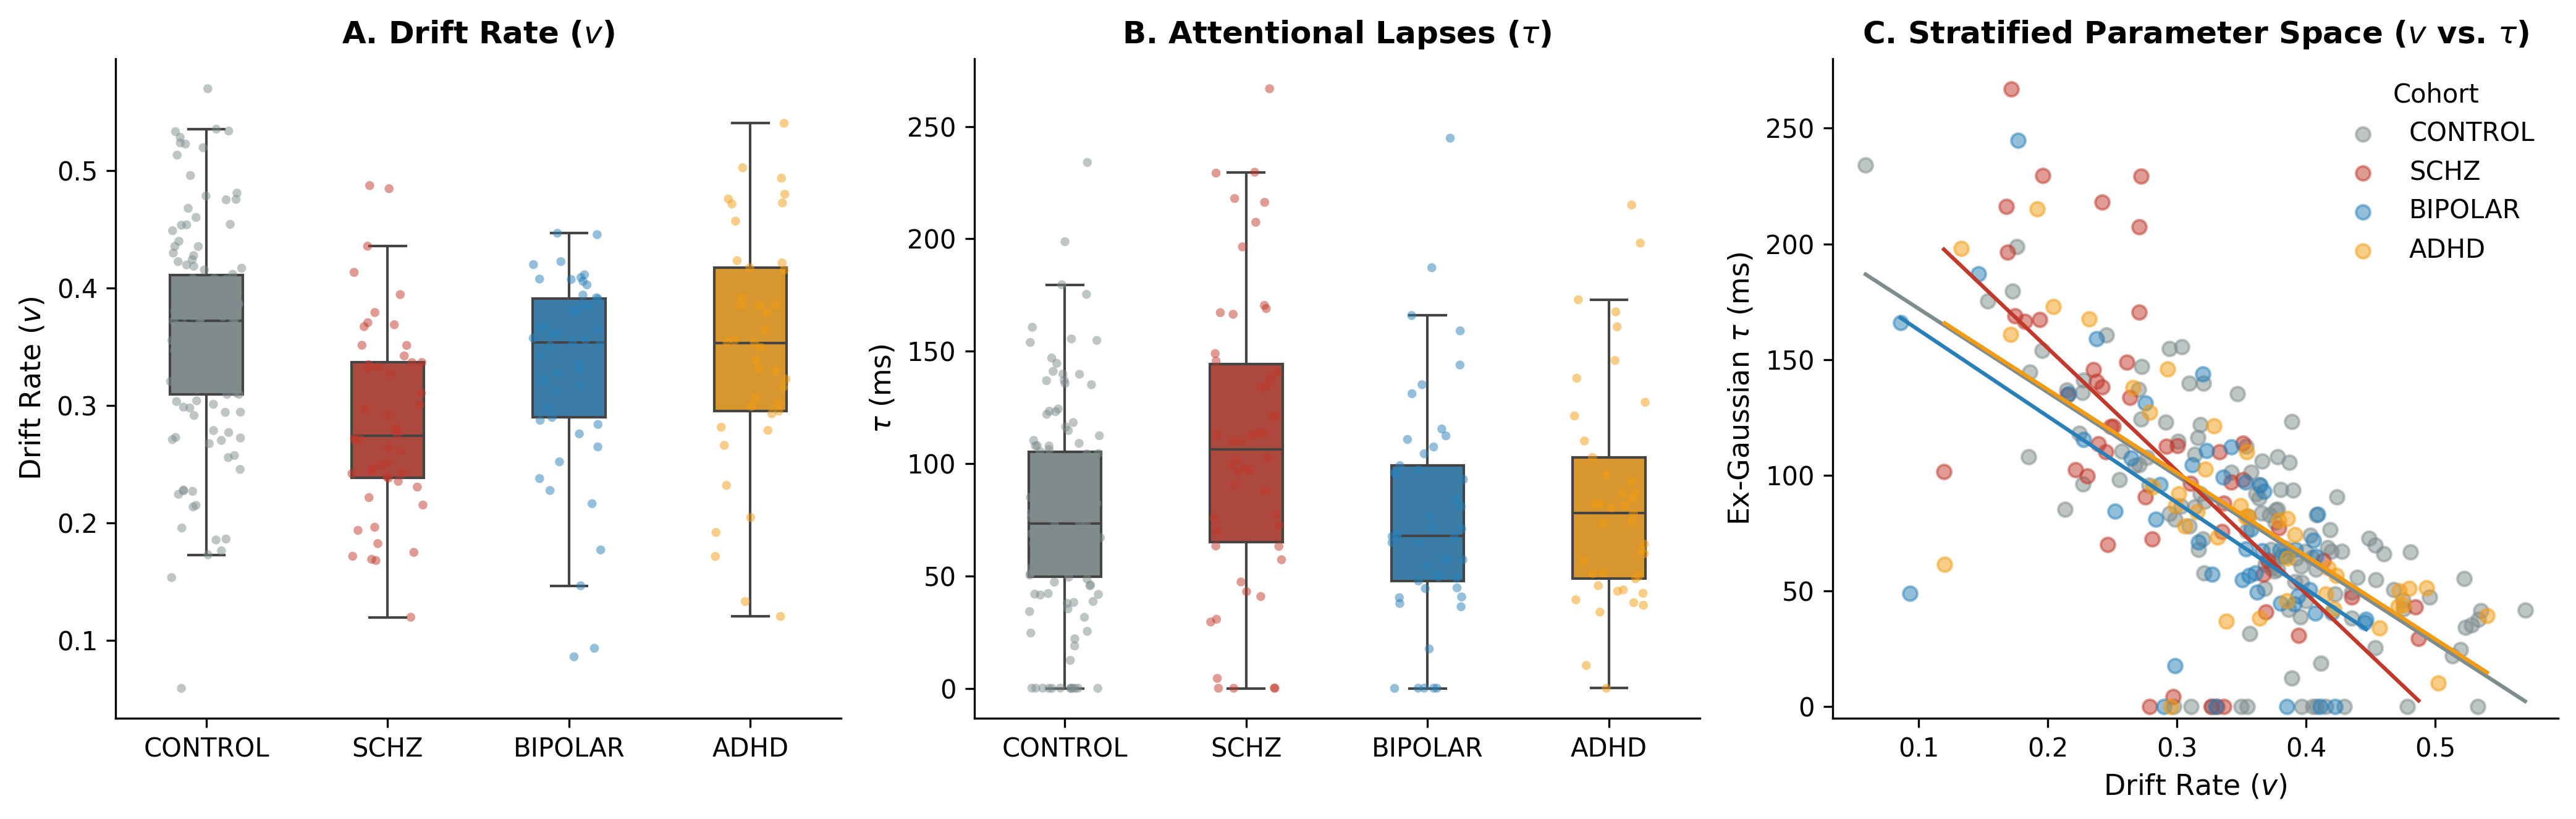

<Figure size 1920x1440 with 0 Axes>

In [ ]:
# Prefix strings with r (raw string) so \t doesn't evaluate as a tab
axes[1].set_title(r"B. Attentional Lapses ($\tau$)", fontsize=12, fontweight="bold")
axes[1].set_ylabel(r"$\tau$ (ms)", fontsize=11)

axes[2].set_title(r"C. Stratified Parameter Space ($v$ vs. $\tau$)", fontsize=12, fontweight="bold")
axes[2].set_ylabel(r"Ex-Gaussian $\tau$ (ms)", fontsize=11)

plt.tight_layout()
fig.savefig("Figure_1_Stratified_Clean.png", dpi=300, bbox_inches="tight")
display(fig)

Retained N = 46 schizophrenia patients with valid CPZ.
Drift Rate (v): beta = 0.00003, p = 0.1106
Tau:            beta = -0.02859, p = 0.2845


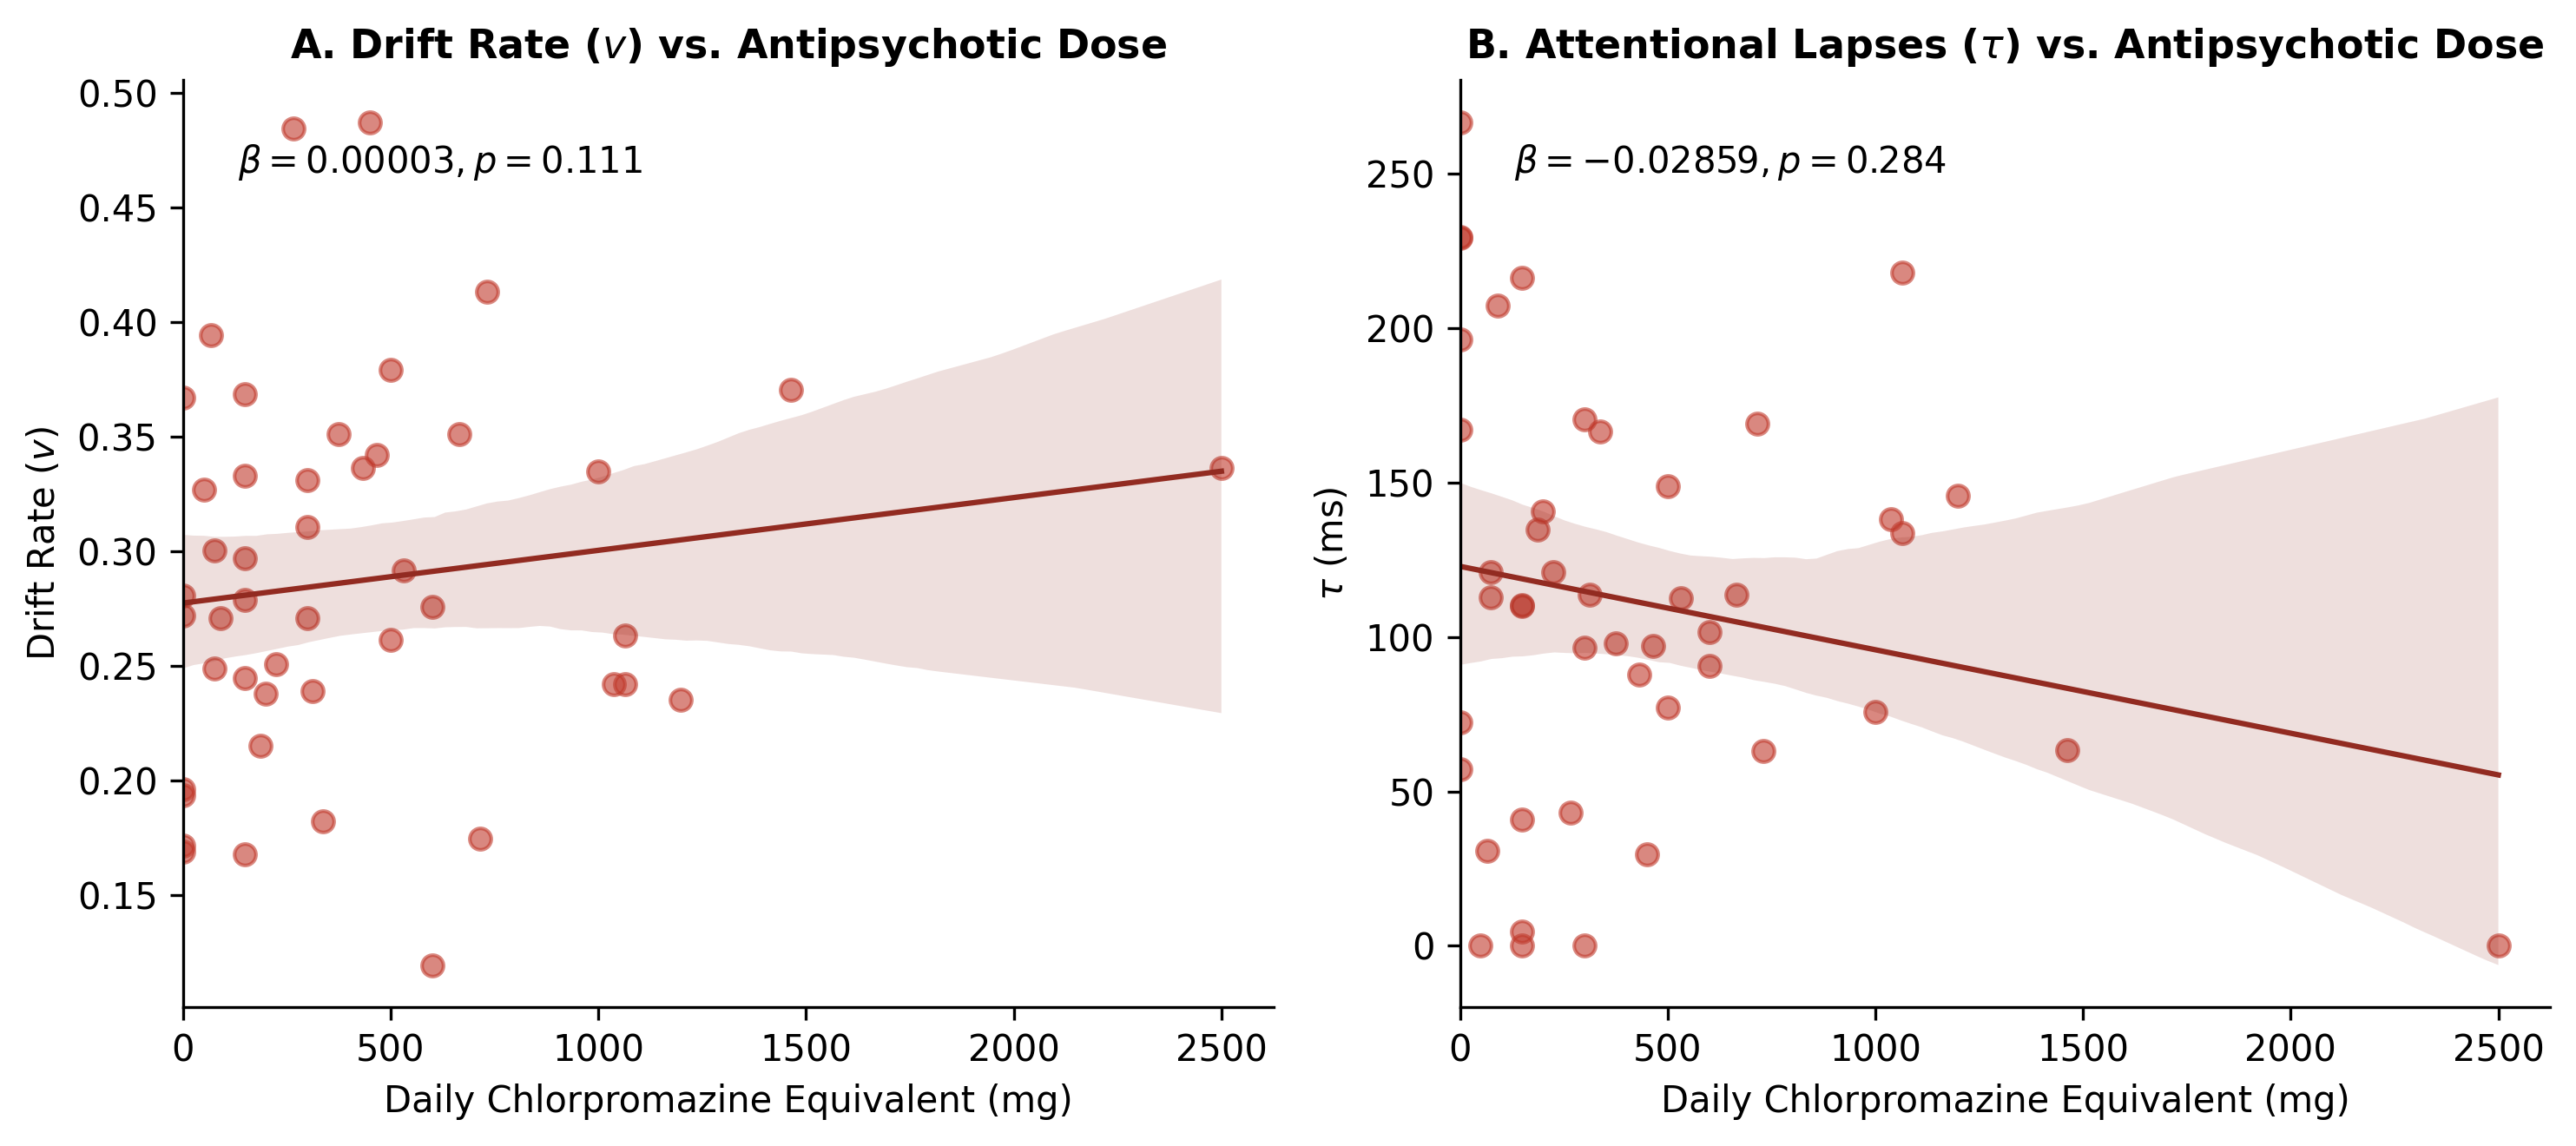

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# 1. Filter to valid clinical range
schz_clean = ucla_master[
    (ucla_master["diagnosis"] == "SCHZ") &
    (ucla_master["cpz_equivalent"] >= 0) &
    (ucla_master["cpz_equivalent"] <= 2500)
].dropna(subset=["v", "tau", "cpz_equivalent"])

print(f"Retained N = {len(schz_clean)} schizophrenia patients with valid CPZ.")

# 2. Re-run multivariable regressions on clean data
m_v = smf.ols("v ~ cpz_equivalent + age + sex + wais_vocab_raw", data=schz_clean).fit(cov_type="HC3")
m_tau = smf.ols("tau ~ cpz_equivalent + age + sex + wais_vocab_raw", data=schz_clean).fit(cov_type="HC3")

beta_v, p_v = m_v.params["cpz_equivalent"], m_v.pvalues["cpz_equivalent"]
beta_tau, p_tau = m_tau.params["cpz_equivalent"], m_tau.pvalues["cpz_equivalent"]

print(f"Drift Rate (v): beta = {beta_v:.5f}, p = {p_v:.4f}")
print(f"Tau:            beta = {beta_tau:.5f}, p = {p_tau:.4f}")

# 3. Re-plot without the outlier
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=300)

# Panel A: Drift Rate vs CPZ
sns.regplot(
    data=schz_clean, x="cpz_equivalent", y="v", ax=axes[0],
    scatter_kws={"alpha": 0.6, "color": "#C0392B", "s": 35},
    line_kws={"color": "#922B21", "linewidth": 1.5},
    ci=95, truncate=True
)
axes[0].set_title(r"A. Drift Rate ($v$) vs. Antipsychotic Dose", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Daily Chlorpromazine Equivalent (mg)", fontsize=10)
axes[0].set_ylabel(r"Drift Rate ($v$)", fontsize=10)
axes[0].set_xlim(left=0)
axes[0].text(0.05, 0.90, f"$\\beta = {beta_v:.5f}, p = {p_v:.3f}$", transform=axes[0].transAxes, fontsize=10)
sns.despine(ax=axes[0])

# Panel B: Tau vs CPZ
sns.regplot(
    data=schz_clean, x="cpz_equivalent", y="tau", ax=axes[1],
    scatter_kws={"alpha": 0.6, "color": "#C0392B", "s": 35},
    line_kws={"color": "#922B21", "linewidth": 1.5},
    ci=95, truncate=True
)
axes[1].set_title(r"B. Attentional Lapses ($\tau$) vs. Antipsychotic Dose", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Daily Chlorpromazine Equivalent (mg)", fontsize=10)
axes[1].set_ylabel(r"$\tau$ (ms)", fontsize=10)
axes[1].set_xlim(left=0)
axes[1].text(0.05, 0.90, f"$\\beta = {beta_tau:.5f}, p = {p_tau:.3f}$", transform=axes[1].transAxes, fontsize=10)
sns.despine(ax=axes[1])

plt.tight_layout()
fig.savefig("Supplementary_Figure_CPZ_Sensitivity_Clean.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
print("=== 1. DIAGNOSTIC CONTRASTS VS. CONTROL (ADJUSTED) ===")
if "results_table_adj" in globals():
    cols = [c for c in ["Group", "Outcome", "beta", "se", "t", "p", "p_fdr", "cohens_d"] if c in results_table_adj.columns]
    disp = results_table_adj[cols].copy()
    num_cols = disp.select_dtypes(include=[np.number]).columns
    disp[num_cols] = disp[num_cols].round(3)
    print(disp.to_string(index=False))

print("\n=== 2. WITHIN-COHORT STRATIFIED REGRESSIONS (tau ~ v) ===")
if "strat_df" in globals():
    print(strat_df.to_string(index=False))

print("\n=== 3. CLASSIFICATION AUC (SCHZ vs. BIPOLAR) ===")
if "auc_raw" in globals() and "auc_comp" in globals():
    print(f"Mean Go RT AUC:        {np.mean(auc_raw):.3f} ± {np.std(auc_raw):.3f}")
    print(f"Computational DDM+Tau: {np.mean(auc_comp):.3f} ± {np.std(auc_comp):.3f}")

print("\n=== 4. SCHIZOPHRENIA CPZ SENSITIVITY ===")
if "schz_df" in globals() and "cpz_equivalent" in schz_df.columns:
    import statsmodels.formula.api as smf
    for param in ["v", "tau", "Ter"]:
        if param in schz_df.columns:
            m = smf.ols(f"{param} ~ cpz_equivalent + age + sex + wais_vocab_raw", data=schz_df).fit(cov_type="HC3")
            print(f"{param:<5} | CPZ beta = {m.params['cpz_equivalent']:>8.5f} | t = {m.tvalues['cpz_equivalent']:>6.3f} | p = {m.pvalues['cpz_equivalent']:.4f}")

=== 1. DIAGNOSTIC CONTRASTS VS. CONTROL (ADJUSTED) ===
  Group    Outcome   beta     se      t     p
   SCHZ go_rt_mean 63.263 25.079  2.523 0.012
BIPOLAR go_rt_mean 32.876 17.281  1.902 0.057
   ADHD go_rt_mean 13.151 19.976  0.658 0.510
   SCHZ        tau 29.417 11.200  2.626 0.009
BIPOLAR        tau -1.632  8.661 -0.188 0.851
   ADHD        tau  6.232  8.873  0.702 0.482
   SCHZ          v -0.045  0.017 -2.612 0.009
BIPOLAR          v -0.023  0.014 -1.628 0.104
   ADHD          v -0.012  0.018 -0.681 0.496
   SCHZ          a  0.009  0.004  2.032 0.042
BIPOLAR          a  0.003  0.004  0.795 0.426
   ADHD          a -0.003  0.004 -0.804 0.421
   SCHZ        Ter 22.267 17.485  1.274 0.203
BIPOLAR        Ter 18.316 10.266  1.784 0.074
   ADHD        Ter 15.234 13.800  1.104 0.270
   SCHZ       ssrt 64.270 37.785  1.701 0.089
BIPOLAR       ssrt 11.903 15.253  0.780 0.435
   ADHD       ssrt -0.014 13.297 -0.001 0.999

=== 2. WITHIN-COHORT STRATIFIED REGRESSIONS (tau ~ v) ===
 Cohort   N 

In [ ]:
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

key_metrics = [
    c for c in METRICS
    if any(k in c.lower() for k in ["mean_go_rt", "tau_", "ez_v", "ez_ter", "ez_a", "ssrt"])
]

group_pairs = [
    ("SCHZ", "ADHD"),
    ("SCHZ", "BIPOLAR"),
    ("BIPOLAR", "ADHD"),
    ("SCHZ", "CONTROL"),
    ("ADHD", "CONTROL"),
    ("BIPOLAR", "CONTROL"),
]

contrast_rows = []
for metric in key_metrics:
    sub = df[[metric, GROUP_COL] + COVARIATES].dropna().copy()
    for g1, g2 in group_pairs:
        if g1 not in sub[GROUP_COL].values or g2 not in sub[GROUP_COL].values:
            continue
        formula = f"{metric} ~ C({GROUP_COL}, Treatment(reference='{g2}')) + age + C(sex) + voc_totalraw"
        fit = smf.ols(formula, data=sub).fit(cov_type="HC3")
        term = f"C({GROUP_COL}, Treatment(reference='{g2}'))[T.{g1}]"

        b = fit.params[term]
        ci_low, ci_high = fit.conf_int().loc[term]
        y1 = sub.loc[sub[GROUP_COL] == g1, metric]
        y2 = sub.loc[sub[GROUP_COL] == g2, metric]
        n1, n2 = len(y1), len(y2)
        s_pooled = np.sqrt(((n1 - 1) * y1.var(ddof=1) + (n2 - 1) * y2.var(ddof=1)) / (n1 + n2 - 2))
        j_corr = 1.0 - 3.0 / (4.0 * (n1 + n2 - 2) - 1.0)

        contrast_rows.append({
            "metric": metric,
            "contrast": f"{g1} vs {g2}",
            "n1": n1,
            "n2": n2,
            "b": b,
            "se_hc3": fit.bse[term],
            "ci_low": ci_low,
            "ci_high": ci_high,
            "t": fit.tvalues[term],
            "p_raw": fit.pvalues[term],
            "hedges_g_adj": (b / s_pooled) * j_corr,
        })

contrasts_df = pd.DataFrame(contrast_rows)
patient_mask = ~contrasts_df["contrast"].str.contains("CONTROL")
contrasts_df.loc[patient_mask, "p_fdr_patient"] = multipletests(
    contrasts_df.loc[patient_mask, "p_raw"], method="fdr_bh"
)[1]
contrasts_df.loc[patient_mask, "p_holm_patient"] = multipletests(
    contrasts_df.loc[patient_mask, "p_raw"], method="holm"
)[1]
print("UCLA CNP pairwise contrasts")
print(contrasts_df.to_string(index=False, float_format="%.4f"))

def partial_spearman(data, x_col, y_col, covs):
    d = data[[x_col, y_col] + covs].dropna().copy()
    n = len(d)
    if n < len(covs) + 5:
        return np.nan, np.nan, n
    rx = stats.rankdata(d[x_col])
    ry = stats.rankdata(d[y_col])
    X = pd.get_dummies(d[covs], drop_first=True, dtype=float)
    for col in X.columns:
        if X[col].nunique() > 2:
            X[col] = stats.rankdata(X[col])
    X = sm.add_constant(X.to_numpy())
    res_x = sm.OLS(rx, X).fit().resid
    res_y = sm.OLS(ry, X).fit().resid
    r = np.corrcoef(res_x, res_y)[0, 1]
    df_res = n - X.shape[1] - 1
    t_stat = r * np.sqrt(df_res / max(1e-12, 1.0 - r ** 2))
    p = 2.0 * stats.t.sf(abs(t_stat), df=df_res)
    return r, p, n

cnp_group_scales = {
    "SCHZ": ["sans_total", "saps_total", "bprs_total", "bprs_negative", "bprs_positive", "factor_avolition", "factor_alogia", "factor_anhedonia", "factor_bluntaffect", "factor_attention"],
    "ADHD": ["asrs_score"],
    "BIPOLAR": ["bprs_total", "bprs_mania", "bprs_depanx", "bprs_positive", "bprs_negative"],
}

symp_rows = []
for grp, scales in cnp_group_scales.items():
    sub_grp = df[df[GROUP_COL] == grp]
    for scale in [s for s in scales if s in sub_grp.columns]:
        for metric in key_metrics:
            d = sub_grp[[metric, scale] + COVARIATES].dropna().copy()
            if len(d) < 12 or d[scale].std() == 0:
                continue
            rho, p_rho, n = partial_spearman(d, scale, metric, COVARIATES)
            d["y_z"] = (d[metric] - d[metric].mean()) / d[metric].std(ddof=1)
            d["x_z"] = (d[scale] - d[scale].mean()) / d[scale].std(ddof=1)
            fit = smf.ols("y_z ~ x_z + age + C(sex) + voc_totalraw", data=d).fit(cov_type="HC3")
            symp_rows.append({
                "cohort": "UCLA_CNP",
                "group": grp,
                "scale": scale,
                "metric": metric,
                "n": n,
                "partial_rho": rho,
                "p_rho": p_rho,
                "beta_hc3": fit.params["x_z"],
                "p_beta": fit.pvalues["x_z"],
            })

washu_metrics = [c for c in ["NBack_Mean_RT_ms", "NBack_EZ_v", "NBack_EZ_Ter_ms", "NBack_EZ_a", "NBack_tau_mle", "NBack_Load2_minus_0_RT_ms"] if c in washu_clean.columns]
washu_scales = [c for c in ["z_pos_4grp", "z_neg_4grp", "z_dis_4grp"] if c in washu_clean.columns]
washu_scz = washu_clean[washu_clean["condit"] == "SCZ"].copy()
for col in washu_metrics + washu_scales + ["age", "WAIS_VOCAB_SCALED"]:
    if col in washu_scz.columns:
        washu_scz[col] = pd.to_numeric(washu_scz[col], errors="coerce")

for scale in washu_scales:
    for metric in washu_metrics:
        d = washu_scz[[metric, scale, "age", "gender", "WAIS_VOCAB_SCALED"]].dropna().copy()
        if len(d) < 10 or d[scale].std() == 0:
            continue
        rho, p_rho, n = partial_spearman(d, scale, metric, ["age", "gender", "WAIS_VOCAB_SCALED"])
        d["y_z"] = (d[metric] - d[metric].mean()) / d[metric].std(ddof=1)
        d["x_z"] = (d[scale] - d[scale].mean()) / d[scale].std(ddof=1)
        fit = smf.ols("y_z ~ x_z + age + C(gender) + WAIS_VOCAB_SCALED", data=d).fit(cov_type="HC3")
        symp_rows.append({
            "cohort": "WashU_ds000115",
            "group": "SCZ",
            "scale": scale,
            "metric": metric,
            "n": n,
            "partial_rho": rho,
            "p_rho": p_rho,
            "beta_hc3": fit.params["x_z"],
            "p_beta": fit.pvalues["x_z"],
        })

symp_df = pd.DataFrame(symp_rows)
symp_df["p_rho_fdr"] = symp_df.groupby(["cohort", "group"])["p_rho"].transform(
    lambda s: multipletests(s, method="fdr_bh")[1]
)
symp_df["p_beta_fdr"] = symp_df.groupby(["cohort", "group"])["p_beta"].transform(
    lambda s: multipletests(s, method="fdr_bh")[1]
)
print("\nSymptom severity correlations")
print(symp_df.to_string(index=False, float_format="%.4f"))

var_rows = []
for sid, g in washu_blocks.groupby("participant_id"):
    total_ss = ((g["median_rt_ms"] - g["median_rt_ms"].mean()) ** 2).sum()
    load_ss = ((g.groupby("load")["median_rt_ms"].transform("mean") - g["median_rt_ms"].mean()) ** 2).sum()
    stim_ss = ((g.groupby("stim_type")["median_rt_ms"].transform("mean") - g["median_rt_ms"].mean()) ** 2).sum()
    var_rows.append({
        "participant_id": sid,
        "group": g["group"].iloc[0],
        "frac_var_load": load_ss / total_ss if total_ss > 0 else np.nan,
        "frac_var_stim": stim_ss / total_ss if total_ss > 0 else np.nan,
    })

var_df = pd.DataFrame(var_rows)
print("\nWashU 6-block RT variance explained by N-back load vs target/nontarget")
print(var_df.groupby("group")[["frac_var_load", "frac_var_stim"]].agg(["mean", "median", "std"]).to_string(float_format="%.3f"))

washu_blocks["ies_ms"] = washu_blocks["median_rt_ms"] / washu_blocks["acc"].clip(lower=0.5)
load_summary = washu_blocks.groupby(["participant_id", "group", "age", "sex", "load"], as_index=False)[["median_rt_ms", "acc", "ies_ms"]].mean()

load_rows = []
for load_val, d in load_summary.groupby("load"):
    for col in ["median_rt_ms", "acc", "ies_ms"]:
        fit = smf.ols(f"{col} ~ C(group, Treatment(reference='CON')) + age + C(sex)", data=d).fit(cov_type="HC3")
        for term in fit.params.index:
            if "Treatment(reference='CON')" not in term:
                continue
            load_rows.append({
                "load": load_val,
                "metric": col,
                "contrast": term.split("[T.")[-1].rstrip("]") + " vs CON",
                "b": fit.params[term],
                "se_hc3": fit.bse[term],
                "t": fit.tvalues[term],
                "p": fit.pvalues[term],
            })

print("\nWashU load-stratified robustness models (age + sex adjusted, HC3)")
print(pd.DataFrame(load_rows).to_string(index=False, float_format="%.4f"))

UCLA CNP pairwise contrasts
              metric           contrast  n1  n2        b  se_hc3    ci_low  ci_high       t  p_raw  hedges_g_adj  p_fdr_patient  p_holm_patient
       Mean_Go_RT_ms       SCHZ vs ADHD  50  41  50.1121 30.9859  -10.6191 110.8434  1.6173 0.1058        0.3875         0.2775          1.0000
       Mean_Go_RT_ms    SCHZ vs BIPOLAR  50  49  30.3870 27.0877  -22.7039  83.4779  1.1218 0.2619        0.2512         0.4309          1.0000
       Mean_Go_RT_ms    BIPOLAR vs ADHD  49  41  19.7251 23.5134  -26.3603  65.8105  0.8389 0.4015        0.1769         0.5688          1.0000
       Mean_Go_RT_ms    SCHZ vs CONTROL  50 126  63.2627 25.0788   14.1092 112.4161  2.5226 0.0117        0.5509            NaN             NaN
       Mean_Go_RT_ms    ADHD vs CONTROL  41 126  13.1506 19.9763  -26.0022  52.3033  0.6583 0.5103        0.1203            NaN             NaN
       Mean_Go_RT_ms BIPOLAR vs CONTROL  49 126  32.8757 17.2808   -0.9940  66.7454  1.9024 0.0571        0.

In [ ]:
print("Spearman(EZ_v, EZ_a) check:")
for task in ["LabSST", "TaskSwitch"]:
    r, p = stats.spearmanr(df[f"{task}_EZ_v"], df[f"{task}_EZ_a"], nan_policy="omit")
    print(f"  {task}: rho={r:.6f}, p={p:.2e}")
r_w, p_w = stats.spearmanr(washu_clean["NBack_EZ_v"], washu_clean["NBack_EZ_a"], nan_policy="omit")
print(f"  WashU NBack: rho={r_w:.6f}, p={p_w:.2e}")

primary_metrics = ["LabSST_tau_mle", "LabSST_EZ_v", "LabSST_EZ_Ter_ms", "sst_ses_ssrt"]
prim_c = contrasts_df[
    contrasts_df["metric"].isin(primary_metrics)
    & ~contrasts_df["contrast"].str.contains("CONTROL")
].copy()
prim_c["p_fdr_primary"] = multipletests(prim_c["p_raw"], method="fdr_bh")[1]
prim_c["p_holm_primary"] = multipletests(prim_c["p_raw"], method="holm")[1]
print("\nPrimary LabSST patient-vs-patient contrasts (12-test family)")
print(prim_c[["metric", "contrast", "b", "ci_low", "ci_high", "t", "p_raw", "p_fdr_primary", "hedges_g_adj"]].to_string(index=False, float_format="%.4f"))

primary_scales = {
    "SCHZ": ["sans_total", "saps_total", "bprs_total"],
    "ADHD": ["asrs_score"],
    "BIPOLAR": ["bprs_total", "bprs_positive", "bprs_depanx", "bprs_mania"],
}
prim_s = symp_df[
    (symp_df["cohort"] == "UCLA_CNP")
    & symp_df["metric"].isin(primary_metrics)
    & symp_df.apply(lambda r: r["scale"] in primary_scales.get(r["group"], []), axis=1)
].copy()
prim_s["p_rho_fdr_primary"] = prim_s.groupby("group")["p_rho"].transform(
    lambda s: multipletests(s, method="fdr_bh")[1]
)
prim_s["p_beta_fdr_primary"] = prim_s.groupby("group")["p_beta"].transform(
    lambda s: multipletests(s, method="fdr_bh")[1]
)
print("\nPrimary UCLA CNP symptom correlations")
print(prim_s[["group", "scale", "metric", "n", "partial_rho", "p_rho", "p_rho_fdr_primary", "beta_hc3", "p_beta", "p_beta_fdr_primary"]].to_string(index=False, float_format="%.4f"))

washu_direct = []
for load_val, d in load_summary.groupby("load"):
    for col in ["median_rt_ms", "acc", "ies_ms"]:
        fit = smf.ols(f"{col} ~ C(group, Treatment(reference='SCZ-SIB')) + age + C(sex)", data=d).fit(cov_type="HC3")
        term = "C(group, Treatment(reference='SCZ-SIB'))[T.SCZ]"
        washu_direct.append({
            "load": load_val,
            "metric": col,
            "contrast": "SCZ vs SCZ-SIB",
            "b": fit.params[term],
            "se_hc3": fit.bse[term],
            "t": fit.tvalues[term],
            "p": fit.pvalues[term],
        })
print("\nWashU direct SCZ vs SCZ-SIB contrasts (age + sex adjusted, HC3)")
print(pd.DataFrame(washu_direct).to_string(index=False, float_format="%.4f"))

Spearman(EZ_v, EZ_a) check:
  LabSST: rho=-1.000000, p=0.00e+00
  TaskSwitch: rho=-1.000000, p=0.00e+00
  WashU NBack: rho=-0.166102, p=1.02e-01

Primary LabSST patient-vs-patient contrasts (12-test family)
          metric        contrast        b   ci_low  ci_high       t  p_raw  p_fdr_primary  hedges_g_adj
    sst_ses_ssrt    SCHZ vs ADHD  25.4528   6.5512  44.3544  2.6393 0.0083         0.0499        0.6011
    sst_ses_ssrt SCHZ vs BIPOLAR  25.0884   4.8301  45.3467  2.4273 0.0152         0.0520        0.5141
    sst_ses_ssrt BIPOLAR vs ADHD   0.3644 -17.3674  18.0961  0.0403 0.9679         0.9679        0.0081
  LabSST_tau_mle    SCHZ vs ADHD  26.2594   4.6306  47.8882  2.3796 0.0173         0.0520        0.5344
  LabSST_tau_mle SCHZ vs BIPOLAR  34.0452  13.4105  54.6799  3.2337 0.0012         0.0147        0.7012
  LabSST_tau_mle BIPOLAR vs ADHD  -7.7858 -24.9254   9.3537 -0.8903 0.3733         0.5386       -0.1884
     LabSST_EZ_v    SCHZ vs ADHD  -0.0292  -0.0561  -0.0023 -2.12

In [ ]:
env_df = pd.read_csv(DATA_DIR / "ucla_cnp_cross_task_env_extracted.csv")
print("env_df columns:", list(env_df.columns))
for task in ["LabSST", "TaskSwitch"]:
    prod = env_df[f"{task}_EZ_v"] * env_df[f"{task}_EZ_a"]
    print(f"{task} (v * a) unique rounded:", prod.dropna().round(6).unique()[:5])

env_df columns: ['participant_id', 'LabSST_mu_mle', 'LabSST_sigma_mle', 'LabSST_tau_mle', 'LabSST_EZ_v', 'LabSST_EZ_a', 'LabSST_EZ_Ter_ms', 'TaskSwitch_mu_mle', 'TaskSwitch_sigma_mle', 'TaskSwitch_tau_mle', 'TaskSwitch_EZ_v', 'TaskSwitch_EZ_a', 'TaskSwitch_EZ_Ter_ms']
LabSST (v * a) unique rounded: [0.036636]
TaskSwitch (v * a) unique rounded: [0.036636]


In [ ]:
cols = [
    "sst_ses_mean_rt",
    "sst_ses_stdev_rt",
    "sst_ses_percent_go_response",
    "sst_ses_direction_errors",
    "sst_bk1_direction_errors",
    "sst_bk2_direction_errors",
    "sst_bk1_endtrial",
    "sst_bk2_endtrial",
]
print(df[cols].describe().T[["count", "min", "50%", "max"]].to_string(float_format="%.4f"))

exg_mean = df["LabSST_mu_mle"] + df["LabSST_tau_mle"]
exg_sd = np.sqrt(df["LabSST_sigma_mle"] ** 2 + df["LabSST_tau_mle"] ** 2)
m = pd.DataFrame({
    "sst_mean": df["sst_ses_mean_rt"],
    "exg_mean": exg_mean,
    "sst_sd": df["sst_ses_stdev_rt"],
    "exg_sd": exg_sd,
}).dropna()

print("corr(sst_ses_mean_rt, LabSST_mu+tau):", f"{m['sst_mean'].corr(m['exg_mean']):.4f}")
print("corr(sst_ses_stdev_rt, LabSST_exg_sd):", f"{m['sst_sd'].corr(m['exg_sd']):.4f}")
print("median abs diff mean (ms):", f"{(m['sst_mean'] - m['exg_mean']).abs().median():.2f}")
print("median abs diff sd (ms):", f"{(m['sst_sd'] - m['exg_sd']).abs().median():.2f}")

                               count      min      50%       max
sst_ses_mean_rt             270.0000 377.8903 587.2839 1012.0000
sst_ses_stdev_rt            270.0000  44.7530 125.6522  300.4470
sst_ses_percent_go_response 270.0000   0.8333   0.9948    1.0000
sst_ses_direction_errors    270.0000   0.0000   0.0000   11.0000
sst_bk1_direction_errors    270.0000   0.0000   0.0000   12.0000
sst_bk2_direction_errors    270.0000   0.0000   0.0000   10.0000
sst_bk1_endtrial            270.0000 128.0000 128.0000  128.0000
sst_bk2_endtrial            270.0000 128.0000 128.0000  128.0000
corr(sst_ses_mean_rt, LabSST_mu+tau): 0.4880
corr(sst_ses_stdev_rt, LabSST_exg_sd): 0.5575
median abs diff mean (ms): 92.85
median abs diff sd (ms): 27.34


In [ ]:
exg_mean = df["LabSST_mu_mle"] + df["LabSST_tau_mle"]
exg_sd = np.sqrt(df["LabSST_sigma_mle"] ** 2 + df["LabSST_tau_mle"] ** 2)
for ref_mean, ref_sd, label in [
    ("Mean_Go_RT_ms", "SD_Go_RT_ms", "scanner_SST"),
    ("sst_ses_mean_rt", "sst_ses_stdev_rt", "stopsignal_tsv"),
]:
    m = pd.DataFrame({
        "ref_m": df[ref_mean], "exg_m": exg_mean,
        "ref_s": df[ref_sd], "exg_s": exg_sd,
    }).dropna()
    print(
        f"LabSST vs {label}: r_mean={m['ref_m'].corr(m['exg_m']):.4f}, "
        f"med_diff_mean={(m['ref_m'] - m['exg_m']).abs().median():.2f} ms, "
        f"r_sd={m['ref_s'].corr(m['exg_s']):.4f}"
    )

err_cols = ["sst_bk1_direction_errors", "sst_bk2_direction_errors", "sst_ses_direction_errors", "sst_ses_percent_go_response"]
nz = df.loc[df["sst_ses_direction_errors"] > 0, err_cols].head(8)
print("\nnon-zero direction error rows:")
print(nz.to_string(index=False))

# Infer whether sst_ses_direction_errors is a block average count (out of 96) or total count (out of 192)
bk_sum = df["sst_bk1_direction_errors"] + df["sst_bk2_direction_errors"]
bk_avg = bk_sum / 2.0
ses_err = df["sst_ses_direction_errors"]
if (ses_err - bk_avg).abs().dropna().max() < 0.05:
    dir_err_total = bk_sum
    err_mode = "mean_per_block_count"
elif (ses_err - bk_sum).abs().dropna().max() < 0.05:
    dir_err_total = ses_err
    err_mode = "total_count"
else:
    dir_err_total = ses_err
    err_mode = "check_unit"
print("direction error mode:", err_mode)

n_go_total = 192.0
n_go_resp = df["sst_ses_percent_go_response"] * n_go_total
df["sst_ses_Pc_emp"] = ((n_go_resp - dir_err_total) / n_go_total).clip(lower=0.501, upper=1.0)
print("empirical Pc summary:", df["sst_ses_Pc_emp"].describe().to_dict())

def ez_diffusion(pc, mrt_s, vrt_s2, n_trials=192, s=0.1):
    if pd.isna(pc) or pd.isna(mrt_s) or pd.isna(vrt_s2) or vrt_s2 <= 0:
        return np.nan, np.nan, np.nan
    if pc >= 1.0:
        pc = 1.0 - 1.0 / (2.0 * n_trials)
    elif pc <= 0.5:
        pc = 0.5 + 1.0 / (2.0 * n_trials)
    s2 = s ** 2
    L = np.log(pc / (1.0 - pc))
    x = L * (L * pc ** 2 - L * pc + pc - 0.5) / vrt_s2
    if x <= 0:
        return np.nan, np.nan, np.nan
    v = np.sign(pc - 0.5) * s * (x ** 0.25)
    a = s2 * L / v
    y = -v * a / s2
    mdt = (a / (2.0 * v)) * ((1.0 - np.exp(y)) / (1.0 + np.exp(y)))
    return v, a, (mrt_s - mdt) * 1000.0

ez_out = df.apply(
    lambda r: ez_diffusion(
        r["sst_ses_Pc_emp"],
        r["sst_ses_mean_rt"] / 1000.0,
        (r["sst_ses_stdev_rt"] / 1000.0) ** 2,
    ),
    axis=1,
    result_type="expand",
)
df[["sst_ses_EZ_v", "sst_ses_EZ_a", "sst_ses_EZ_Ter_ms"]] = ez_out

r_va, p_va = stats.spearmanr(df["sst_ses_EZ_v"], df["sst_ses_EZ_a"], nan_policy="omit")
print(f"\nSpearman(sst_ses_EZ_v, sst_ses_EZ_a): rho={r_va:.4f}, p={p_va:.2e}")

emp_metrics = ["sst_ses_EZ_v", "sst_ses_EZ_a", "sst_ses_EZ_Ter_ms", "sst_ses_ssrt"]
pairs = [
    ("SCHZ", "ADHD"), ("SCHZ", "BIPOLAR"), ("BIPOLAR", "ADHD"),
    ("SCHZ", "CONTROL"), ("ADHD", "CONTROL"), ("BIPOLAR", "CONTROL"),
]
c_rows = []
for metric in emp_metrics:
    sub = df[[metric, GROUP_COL] + COVARIATES].dropna().copy()
    for g1, g2 in pairs:
        fit = smf.ols(
            f"{metric} ~ C({GROUP_COL}, Treatment(reference='{g2}')) + age + C(sex) + voc_totalraw",
            data=sub,
        ).fit(cov_type="HC3")
        term = f"C({GROUP_COL}, Treatment(reference='{g2}'))[T.{g1}]"
        b = fit.params[term]
        ci_low, ci_high = fit.conf_int().loc[term]
        y1 = sub.loc[sub[GROUP_COL] == g1, metric]
        y2 = sub.loc[sub[GROUP_COL] == g2, metric]
        n1, n2 = len(y1), len(y2)
        s_pooled = np.sqrt(((n1 - 1) * y1.var(ddof=1) + (n2 - 1) * y2.var(ddof=1)) / (n1 + n2 - 2))
        g_adj = (b / s_pooled) * (1.0 - 3.0 / (4.0 * (n1 + n2 - 2) - 1.0))
        c_rows.append({
            "metric": metric, "contrast": f"{g1} vs {g2}",
            "b": b, "ci_low": ci_low, "ci_high": ci_high,
            "t": fit.tvalues[term], "p_raw": fit.pvalues[term], "g_adj": g_adj,
        })

emp_c = pd.DataFrame(c_rows)
pmask = ~emp_c["contrast"].str.contains("CONTROL")
emp_c.loc[pmask, "p_fdr_patient"] = multipletests(emp_c.loc[pmask, "p_raw"], method="fdr_bh")[1]
print("\nEmpirical stops_tsv EZ contrasts (age + sex + voc adjusted, HC3)")
print(emp_c.to_string(index=False, float_format="%.4f"))

s_rows = []
for grp, scales in {
    "SCHZ": ["sans_total", "saps_total", "bprs_total"],
    "ADHD": ["asrs_score"],
    "BIPOLAR": ["bprs_total", "bprs_positive", "bprs_depanx", "bprs_mania"],
}.items():
    sub_grp = df[df[GROUP_COL] == grp]
    for scale in scales:
        for metric in ["sst_ses_EZ_v", "sst_ses_EZ_a", "sst_ses_EZ_Ter_ms"]:
            d = sub_grp[[metric, scale] + COVARIATES].dropna().copy()
            if len(d) < 12 or d[scale].std() == 0:
                continue
            rho, p_rho, n = partial_spearman(d, scale, metric, COVARIATES)
            d["y_z"] = (d[metric] - d[metric].mean()) / d[metric].std(ddof=1)
            d["x_z"] = (d[scale] - d[scale].mean()) / d[scale].std(ddof=1)
            fit = smf.ols("y_z ~ x_z + age + C(sex) + voc_totalraw", data=d).fit(cov_type="HC3")
            s_rows.append({
                "group": grp, "scale": scale, "metric": metric, "n": n,
                "partial_rho": rho, "p_rho": p_rho,
                "beta_hc3": fit.params["x_z"], "p_beta": fit.pvalues["x_z"],
            })

emp_s = pd.DataFrame(s_rows)
emp_s["p_rho_fdr"] = emp_s.groupby("group")["p_rho"].transform(lambda s: multipletests(s, method="fdr_bh")[1])
print("\nEmpirical stops_tsv EZ symptom correlations")
print(emp_s.to_string(index=False, float_format="%.4f"))

LabSST vs scanner_SST: r_mean=0.7092, med_diff_mean=40.33 ms, r_sd=0.6499
LabSST vs stopsignal_tsv: r_mean=0.4880, med_diff_mean=92.85 ms, r_sd=0.5575

non-zero direction error rows:
 sst_bk1_direction_errors  sst_bk2_direction_errors  sst_ses_direction_errors  sst_ses_percent_go_response
                      0.0                       1.0                       0.5                     0.994792
                      0.0                       1.0                       0.5                     0.994792
                      1.0                       1.0                       1.0                     0.984375
                      2.0                       0.0                       1.0                     0.984375
                      1.0                       0.0                       0.5                     0.994792
                      0.0                       1.0                       0.5                     0.994792
                      0.0                       1.0                 

In [ ]:
med_tsv = pd.read_csv(DATA_DIR / "medication.tsv", sep="\t", na_values=["n/a", "NA", ""])
print("medication.tsv columns:", list(med_tsv.columns))

scz = df[df[GROUP_COL] == "SCHZ"].copy()
med_cols = [c for c in med_tsv.columns if c != "participant_id" and c in scz.columns]
for col in med_cols:
    vals = scz[col].dropna()
    if len(vals) > 0:
        print(col, "non-null:", len(vals), "sample:", vals.unique()[:5])

medication.tsv columns: ['participant_id', 'med_prn18', 'med_dur1', 'med_use4', 'med_use11', 'med_days5', 'med_use1', 'med_days9', 'med_days8', 'med_use7', 'med_prn15', 'med_dur13', 'med_days18', 'med_use3', 'med_name7', 'med_days17', 'med_dur7', 'med_use8', 'med_days13', 'med_dos9', 'med_dur8', 'med_use13', 'med_days19', 'med_use5', 'med_use6', 'med_prn14', 'med_days16', 'med_dos4', 'med_prn13', 'med_days4', 'med_dos2', 'med_use2', 'med_use12', 'med_prn10', 'med_use20', 'med_dur2', 'med_dur14', 'med_name5', 'med_use9', 'med_dos10', 'med_dur18', 'med_prn7', 'med_name18', 'med_days14', 'med_prn16', 'med_dos18', 'med_dur12', 'med_name14', 'med_dos1', 'med_prn20', 'med_days15', 'med_prn5', 'med_dur17', 'med_dur10', 'med_days11', 'med_name17', 'med_use15', 'med_dur15', 'med_dos14', 'med_days2', 'med_dur11', 'med_prn11', 'med_prn19', 'med_prn6', 'med_days6', 'med_name3', 'med_name1', 'med_name2', 'med_dos3', 'med_days10', 'med_days20', 'med_dur16', 'med_use17', 'med_dur9', 'med_prn17', 'med

In [ ]:
ap_factors = {
    "chlorpromazine": 1.0,
    "thorazine": 1.0,
    "olanzapine": 20.0,
    "zyprexa": 20.0,
    "risperidone": 50.0,
    "risperdal": 50.0,
    "paliperidone": 50.0,
    "invega": 50.0,
    "quetiapine": 1.333,
    "seroquel": 1.333,
    "ziprasidone": 1.667,
    "geodon": 1.667,
    "aripiprazole": 13.333,
    "abilify": 13.333,
    "clozapine": 1.0,
    "clozaril": 1.0,
    "haloperidol": 50.0,
    "haldol": 50.0,
    "fluphenazine": 50.0,
    "prolixin": 50.0,
    "perphenazine": 10.0,
    "trilafon": 10.0,
    "trifluoperazine": 20.0,
    "stelazine": 20.0,
    "thiothixene": 20.0,
    "navane": 20.0,
    "loxapine": 10.0,
    "lurasidone": 5.0,
    "latuda": 5.0,
    "asenapine": 15.0,
    "saphris": 15.0,
    "iloperidone": 25.0,
    "fanapt": 25.0,
    "pimozide": 50.0,
    "thioridazine": 1.0,
}

def compute_cpz_row(row):
    total = 0.0
    on_ap = False
    missing_dose = False
    matched = []
    for i in range(1, 21):
        name_col = f"med_name{i}"
        dos_col = f"med_dos{i}"
        use_col = f"med_use{i}"
        if name_col not in row.index or pd.isna(row[name_col]):
            continue
        use_val = pd.to_numeric(row.get(use_col, np.nan), errors="coerce")
        if pd.notna(use_val) and use_val == 0:
            continue

        raw_name = str(row[name_col]).strip()
        lname = raw_name.lower()
        factor = next((f for k, f in ap_factors.items() if k in lname), None)
        if factor is None:
            continue

        on_ap = True
        dose = pd.to_numeric(row.get(dos_col, np.nan), errors="coerce")
        # CNP encodes missing doses as negative sentinel values (e.g. -9998)
        if pd.isna(dose) or dose < 0:
            missing_dose = True
            matched.append(f"{raw_name}(NA)")
        else:
            total += dose * factor
            matched.append(f"{raw_name}({dose:g}mg)")

    cpz = np.nan if (on_ap and missing_dose and total == 0.0) else total
    return pd.Series({
        "cpz_eq": cpz,
        "on_ap": int(on_ap),
        "ap_missing_dose": int(missing_dose),
        "ap_list": "; ".join(matched),
    })

scz = df[df[GROUP_COL] == "SCHZ"].copy()
scz[["cpz_eq", "on_ap", "ap_missing_dose", "ap_list"]] = scz.apply(compute_cpz_row, axis=1)
scz["log_cpz"] = np.log1p(scz["cpz_eq"])

all_scz_meds = sorted({
    str(v).strip()
    for i in range(1, 21)
    if f"med_name{i}" in scz.columns
    for v in scz[f"med_name{i}"].dropna()
})
unmatched_meds = [m for m in all_scz_meds if not any(k in m.lower() for k in ap_factors)]
print("SCHZ unmatched med names (verify no antipsychotics missed):")
print(unmatched_meds)

print("\nSCHZ CPZ summary:")
print(scz[["cpz_eq", "on_ap", "ap_missing_dose"]].describe().T[["count", "mean", "50%", "max"]].to_string(float_format="%.2f"))
if scz["ap_missing_dose"].sum() > 0:
    print("Rows with AP missing dose:", scz.loc[scz["ap_missing_dose"] == 1, ["participant_id", "ap_list", "cpz_eq"]].to_string(index=False))

check_cols = ["sst_ses_EZ_v", "sst_ses_EZ_a", "sst_ses_EZ_Ter_ms", "sst_ses_ssrt", "LabSST_tau_mle", "saps_total", "sans_total", "bprs_total"]
cpz_rows = []
for col in check_cols:
    rho, p_rho, n = partial_spearman(scz, "cpz_eq", col, COVARIATES)
    d = scz[[col, "log_cpz"] + COVARIATES].dropna().copy()
    d["y_z"] = (d[col] - d[col].mean()) / d[col].std(ddof=1)
    d["x_z"] = (d["log_cpz"] - d["log_cpz"].mean()) / d["log_cpz"].std(ddof=1)
    fit = smf.ols("y_z ~ x_z + age + C(sex) + voc_totalraw", data=d).fit(cov_type="HC3")
    cpz_rows.append({
        "outcome": col, "n": n,
        "partial_rho_cpz": rho, "p_rho": p_rho,
        "beta_log_cpz": fit.params["x_z"], "p_beta": fit.pvalues["x_z"],
    })
print("\nSCHZ CPZ-eq partial correlations (age + sex + voc adjusted)")
print(pd.DataFrame(cpz_rows).to_string(index=False, float_format="%.4f"))

adj_rows = []
for scale in ["saps_total", "bprs_total", "sans_total"]:
    for metric in ["sst_ses_EZ_Ter_ms", "sst_ses_EZ_v", "sst_ses_ssrt", "LabSST_tau_mle"]:
        for cov_label, extra in [("base", []), ("+cpz_eq", ["cpz_eq"]), ("+log_cpz", ["log_cpz"])]:
            covs = COVARIATES + extra
            d = scz[[metric, scale] + covs].dropna().copy()
            rho, p_rho, n = partial_spearman(d, scale, metric, covs)
            d["y_z"] = (d[metric] - d[metric].mean()) / d[metric].std(ddof=1)
            d["x_z"] = (d[scale] - d[scale].mean()) / d[scale].std(ddof=1)
            rhs = "x_z + age + C(sex) + voc_totalraw" + (f" + {extra[0]}" if extra else "")
            fit = smf.ols(f"y_z ~ {rhs}", data=d).fit(cov_type="HC3")
            adj_rows.append({
                "scale": scale, "metric": metric, "model": cov_label, "n": n,
                "partial_rho": rho, "p_rho": p_rho,
                "beta_hc3": fit.params["x_z"], "p_beta": fit.pvalues["x_z"],
            })
print("\nSCHZ symptom correlations before vs after CPZ control")
print(pd.DataFrame(adj_rows).to_string(index=False, float_format="%.4f"))

SCHZ unmatched med names (verify no antipsychotics missed):
['Ambien/ Zolpidem', 'Artane/Trihexyphenidyl', 'Atenolol/ Tenormin', 'Ativan/ Lorazepam', 'Benadryl/ Diphenhydramine', 'Celexa/ Citalopram', 'Clonazepam/ Klonopin', 'Cogentin/ Benztropine', 'Depakote ER/ Divalproex', 'Depakote/ Divalproex', 'Divalproex/ Depakote ER', 'Doxepin/ Sinequan/ Adapin', 'ECT', 'Fluoxetine/Prozac', 'Hydroxyzine/ Atarax/ Vistaril', 'Klonopin/ Clonazepam', 'Lamictal/ Lamotrigine', 'Lamotrigine/ Lamictal', 'Levothyroxine sodium/ Levotabs/ Levothroid/ etc', 'Lexapro/ Escitalopram oxalate', 'Lithium Carbonate/Eskalith/Lithonate/ etc', 'Lorazepam/ Ativan', 'Paroxetine/ Paxil', 'Paxil/ Paroxetine', 'Phentermine Hydrochloride', 'Propranolol/ Inderal', 'Prozac/ Fluoxetine', 'Remeron/ Mirtazapine', 'Restoril/ Temazepam', 'Rozerem', 'Sleep Eze/ Diphenhydramine', 'Synthroid/ Levothyroxine sodium', 'Tegretol/ Carbamazepine', 'Temazepam/ Restoril', 'Topamax/ Topiramate', 'Trazodone/ Desyrel', 'Wellbutrin SR /Bupropi